# Marketing Science Empirical Analysis — Step-by-Step Story Progression

Evaluation of `KEV-0.8B`, `KEV-4B`, and `KEV-9B` across the paper's four-step narrative using two universal metrics shared across all benchmarks: **Population Slope MSE ($\beta\text{ MSE}$)** and **Choice-Distribution KL Divergence ($\text{Choice KL}$)**. All dataset shorthands and citations are defined in **Table 0a** below.

### Narrative Roadmap
- **Table 0a — Datasets**: Shorthand labels, citations, roles, sample sizes, and OLS slope counts.
- **Step 0 — Run & `test_best` Inventory**: Training status (`runs-rorqual/`, `runs-nibi/`) and `test_best/` completion across `Food labels`, `Vaccines`, `Consumer rights`, and `AI & offshoring`.
- **Overview — The Story at a Glance**: Table 0b, Figure 0 (change on `Flights †` vs. held-out test sets for every main regime).
- **Step 1 — Microdata Fine-Tuning Transfers to Unseen Domains**: Table 1, Figure 1 (`Untrained` vs. `Electricity (microdata)`, `Drones (microdata)`, `Drones + Electricity (microdata)`); Choice KL in Table A2.
- **Step 2 — Published OLS Slopes Teach the Study's Preferences**: Table 2, Figure 2 (`Untrained` vs. `Electricity (OLS slopes)` vs. `Electricity (microdata)`); Choice KL in Table A3.
- **Step 3 — Combining Own Microdata With Another Study's OLS Slopes**: Table 3, Figure 3 (`Untrained` vs. `Drones (microdata)` vs. `Drones (microdata) + Electricity (OLS slopes)` vs. `Drones + Electricity (microdata)`); Choice KL in Table A4.
- **Step 4 — Where the OLS Slopes Help (`Flights †`, `Consumer rights`, & `AI & offshoring` by attribute)**: Figure 4 (model − human on `Flights †`), Figure 5 (human and model slopes on `Flights †`), Table 3b & Figure 5b (`Consumer rights` held-out Price vs. non-price attribute groups), Table 3c & Figure 5c (`AI & offshoring` held-out Price vs. job-change attribute groups); full slope tables in Tables A5 (`Vaccines`), A6 (`Flights †`), A8 (`Consumer rights`), and A9 (`AI & offshoring`).
- **Ablation — The KL Anchor** (validation set `Flights †` only): Table 4 (with vs. without the anchor), Figures 6–7 (`Flights †` over training), Table 5 ($\alpha$ sweep); Choice KL in Table A7.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from cycler import cycler

# Repository academic palette ("nature") & neutral tones (cf. code/analysis/wang2026/wang_mnl.py)
PALETTE_NAME = "lancet"
PALETTES = {
    "nature": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
    "lancet": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
}
NEUTRALS = {
    "text": "#2B2B2B",
    "muted": "#52514E",
    "ref_line": "#6E6A64",
    "baseline": "#9A9893",
    "grid": "#D4D2CC",
    "legend_edge": "#E0DED8",
}
PAL = PALETTES[PALETTE_NAME]
plt.rcParams["axes.prop_cycle"] = cycler(color=PAL)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", None)

CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "training"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and training/ at or above {Path.cwd()}")

BETA_TRAINING_DIR = CODE_DIR / "train-notebooks" / "beta-training"
PAPER_DIR = BETA_TRAINING_DIR / "ms_paper_beta_loss"
PAPER_RUNS_ROOT = PAPER_DIR / "runs-rorqual"
# Regime runs pulled from each cluster; one regime run lives in exactly one of these
REGIME_RUN_ROOTS = (PAPER_DIR / "runs-rorqual", PAPER_DIR / "runs-nibi")
LOCAL_PAPER_RUNS_ROOT = PAPER_DIR / "runs"
TEST_BEST_SUBDIR = "test_best"

os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(BETA_TRAINING_DIR), str(PAPER_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from beta_train import runs as run_store
from paper_beta import extract_step0_from_run_dir, load_paper_run

MODEL_SLUGS = ("kev-0.8b", "kev-4b", "kev-9b")
MODEL_DISPLAY = {
    "kev-0.8b": "KEV-0.8B",
    "kev-4b": "KEV-4B",
    "kev-9b": "KEV-9B",
}
VALIDATORS = ("kriner2026", "grummon2025")

REGIME_LABELS = {
    "row1_base_untrained": "Row 1: Untrained",
    "row2_wu_table_anchored": "Row 2: Electricity (OLS slopes, KL = 0.005)",
    "row2_ablation_wu_table_no_kl": "Row 2: Electricity (OLS slopes, no anchor)",
    "row2b_wu_ce_oracle": "Row 2b: Electricity (microdata)",
    "row3_berke_ce_only": "Row 3: Drones (microdata)",
    "row4_hybrid_berke_ce_wu_table_anchored": "Row 4: Drones (microdata) + Electricity (OLS slopes, KL = 0.005)",
    "row4_hybrid_berke_ce_wu_table_no_kl": "Row 4: Drones (microdata) + Electricity (OLS slopes, no anchor)",
    "row5_full_berke_wu_ce_oracle": "Row 5: Drones + Electricity (microdata)",
}
ALL_SLUGS = tuple(REGIME_LABELS.keys())
TRAINED_SLUGS = tuple(k for k in ALL_SLUGS if k != "row1_base_untrained")


def print_caption(label: str, title: str) -> None:
    """APA caption printed above a table or figure: number on one line, brief title on the next."""
    print(label)
    print(title)


def print_note(note: str) -> None:
    """APA general note printed below a table or figure."""
    print(f"Note. {note}")


def load_test_best_entry(run_or_row1_dir: Path, expected_step: int) -> dict | None:
    """Load `test_best/` (`grummon2025`, `covid`, and optional `kantorowicz2026` / `magistro2025`) and verify alignment."""
    test_dir = run_or_row1_dir / TEST_BEST_SUBDIR
    test_json = test_dir / "test.json"
    if not test_json.exists():
        return None
    metrics_csv = test_dir / "metrics.csv"
    betas_csv = test_dir / "betas.csv"
    if not metrics_csv.exists() or not betas_csv.exists():
        raise FileNotFoundError(f"Incomplete test_best directory in {test_dir}")

    test_info = json.loads(test_json.read_text(encoding="utf-8"))
    actual_step = int(test_info["checkpoint_step"])
    if actual_step != expected_step:
        raise ValueError(f"Stale test_best in {test_dir}: checkpoint_step={actual_step}, expected {expected_step}")

    metrics_df = pd.read_csv(metrics_csv).set_index("dataset")
    for ds in ("grummon2025", "covid"):
        if ds not in metrics_df.index:
            raise ValueError(f"Dataset {ds!r} missing from {metrics_csv}")

    betas_df = pd.read_csv(betas_csv)
    required_cols = {"validator", "term", "human_pop_beta", "model_pop_beta"}
    if not required_cols.issubset(betas_df.columns):
        raise ValueError(f"Missing columns in {betas_csv}: expected {required_cols}, got {set(betas_df.columns)}")

    k26_in_metrics = "kantorowicz2026" in metrics_df.index
    k26_in_betas = bool((betas_df["validator"] == "kantorowicz2026").any())
    if k26_in_metrics != k26_in_betas:
        raise ValueError(
            f"Inconsistent kantorowicz2026 state in {test_dir}: "
            f"in metrics.csv={k26_in_metrics}, in betas.csv={k26_in_betas}"
        )
    kantorowicz_betas = (
        betas_df[betas_df["validator"] == "kantorowicz2026"].set_index("term")
        if k26_in_metrics
        else None
    )

    m25_in_metrics = "magistro2025" in metrics_df.index
    m25_in_betas = bool((betas_df["validator"] == "magistro2025").any())
    if m25_in_metrics != m25_in_betas:
        raise ValueError(
            f"Inconsistent magistro2025 state in {test_dir}: "
            f"in metrics.csv={m25_in_metrics}, in betas.csv={m25_in_betas}"
        )
    magistro_betas = (
        betas_df[betas_df["validator"] == "magistro2025"].set_index("term")
        if m25_in_metrics
        else None
    )

    return {
        "metrics_df": metrics_df,
        "covid_betas": betas_df[betas_df["validator"] == "covid"].set_index("term"),
        "grummon_betas": betas_df[betas_df["validator"] == "grummon2025"].set_index("term"),
        "kantorowicz_betas": kantorowicz_betas,
        "has_kantorowicz": k26_in_metrics,
        "magistro_betas": magistro_betas,
        "has_magistro": m25_in_metrics,
    }


def find_run_dir(model_slug: str, slug: str) -> Path:
    """The regime run folder across REGIME_RUN_ROOTS; a path without run.json when the run does not exist yet."""
    found = []
    for root in REGIME_RUN_ROOTS:
        candidate = root / model_slug / slug
        if (candidate / "run.json").exists():
            found.append(candidate)
    if len(found) > 1:
        raise ValueError(f"{model_slug}/{slug} exists in more than one run root: {found}")
    if len(found) == 1:
        return found[0]
    return REGIME_RUN_ROOTS[0] / model_slug / slug


print(f"PAPER_RUNS_ROOT (Row 1, α sweeps): {PAPER_RUNS_ROOT}")
print(f"REGIME_RUN_ROOTS: {[str(r) for r in REGIME_RUN_ROOTS]}")

PAPER_RUNS_ROOT (Row 1, α sweeps): /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual
REGIME_RUN_ROOTS: ['/home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual', '/home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-nibi']


---
## Datasets — Shorthand Reference (Table 0a)

In [2]:
from beta_ols import berke2023 as ds_berke
from beta_ols import covid as ds_covid
from beta_ols import grummon2025 as ds_grummon
from beta_ols import kantorowicz2026 as ds_kantorowicz
from beta_ols import kriner2026 as ds_kriner
from beta_ols import magistro2025 as ds_magistro
from beta_ols import wu2025 as ds_wu

DATASET_SPECS = (
    (
        "Electricity",
        "Wu (2025)",
        "Energy Research & Social Science",
        "Training (microdata or OLS slopes)",
        "Electricity-plan conjoint: monthly bill, renewable share, local renewables",
        ds_wu,
        "CaseID",
        True,
    ),
    (
        "Drones",
        "Berke et al. (2023)",
        "Transportation Research Part C",
        "Training (microdata)",
        "Drone-delivery discrete choice: delivery fee, wait time, privacy",
        ds_berke,
        "ResponseId",
        False,
    ),
    (
        "Food labels",
        "Grummon et al. (2025)",
        "JAMA Network Open",
        "Held-out test",
        "Six-arm nutrition-label trial: front-of-package warning labels vs. control",
        ds_grummon,
        "participantid",
        True,
    ),
    (
        "Vaccines",
        "Kreps et al. (2020)",
        "JAMA Network Open",
        "Held-out test",
        "COVID-19 vaccine conjoint: efficacy, duration, side effects, FDA, origin, endorsements",
        ds_covid,
        "respondent",
        True,
    ),
    (
        "Consumer rights",
        "Kantorowicz-Reznichenko et al. (2026)",
        "Journal of Law and Empirical Analysis",
        "Held-out test",
        "Laptop & laundry-machine conjoints: price, brand, product specs, warranty, privacy, liability, conflict resolution",
        ds_kantorowicz,
        "CASEID",
        True,
    ),
    (
        "AI & offshoring",
        "Magistro et al. (2025)",
        "American Journal of Political Science",
        "Held-out test",
        "Smartphone AI & offshoring conjoint (US & Canada): price, customer service jobs, factory jobs, data science jobs",
        ds_magistro,
        "CASEID",
        True,
    ),
    (
        "Flights †",
        "Goldfarb et al. (2026)",
        "Journal of Cleaner Production",
        "Validation (selects best.pt)",
        "Flight conjoint: price, sustainable aviation fuel, airline, baggage, legroom, seat",
        ds_kriner,
        "respondent",
        True,
    ),
)

dataset_rows = []
for shorthand, citation, journal, role, task_desc, mod, resp_col, uses_slopes in DATASET_SPECS:
    choice_df = mod.load_choice_df()
    n_resp = int(choice_df[resp_col].nunique())
    n_choices = int(len(choice_df))
    if uses_slopes:
        specs = mod.regression_specs(mod.regression_rows(choice_df))
        n_slopes = sum(len(spec.target_labels) for spec in specs.values())
        slopes_str = str(n_slopes)
    else:
        slopes_str = "—"
    dataset_rows.append(
        {
            "Dataset": shorthand,
            "Citation": citation,
            "Journal": journal,
            "Role": role,
            "Choice task & key attributes": task_desc,
            "Respondents": f"{n_resp:,}",
            "Choices": f"{n_choices:,}",
            "OLS slopes": slopes_str,
        }
    )

datasets_summary_df = pd.DataFrame(dataset_rows).set_index("Dataset")
print_caption("Table 0a", "Summary of Training, Validation, and Held-Out Test Datasets")
display(datasets_summary_df)
print_note(
    "Shorthand labels in the first column are used throughout all tables and figures. "
    "Training regimes append the supervision format in parentheses: (microdata) trains on respondent choices via cross-entropy; "
    "(OLS slopes) trains on the 8 published-specification OLS slopes of Wu (2025) while withholding all 18,591 respondent choices. "
    "OLS slopes = number of population regression slopes used in training or evaluation (— for Drones, which enters training only as microdata; "
    "Consumer rights spans two product conjoints of 19 slopes each = 38 total; AI & offshoring spans four country × arm regressions of 8 slopes each = 32 total). "
    "† Flights (Goldfarb et al., 2026) is the validation set used to select each run's checkpoint (best.pt) and to judge the KL anchor ablation."
)

Table 0a
Summary of Training, Validation, and Held-Out Test Datasets


,Citation,Journal,Role,Choice task & key attributes,Respondents,Choices,OLS slopes
Dataset,,,,,,,
Electricity,Wu (2025),Energy Research & Social Science,Training (microdata or OLS slopes),"Electricity-plan conjoint: monthly bill, renewable share, local renewables","1,861","18,591",8
Drones,Berke et al. (2023),Transportation Research Part C,Training (microdata),"Drone-delivery discrete choice: delivery fee, wait time, privacy","3,625","36,297",—
Food labels,Grummon et al. (2025),JAMA Network Open,Held-out test,Six-arm nutrition-label trial: front-of-package warning labels vs. control,"5,633","33,798",5
Vaccines,Kreps et al. (2020),JAMA Network Open,Held-out test,"COVID-19 vaccine conjoint: efficacy, duration, side effects, FDA, origin, endorsements","1,971","9,855",11
Consumer rights,Kantorowicz-Reznichenko et al. (2026),Journal of Law and Empirical Analysis,Held-out test,"Laptop & laundry-machine conjoints: price, brand, product specs, warranty, privacy, liability, conflict resolution","2,242","26,823",38
AI & offshoring,Magistro et al. (2025),American Journal of Political Science,Held-out test,"Smartphone AI & offshoring conjoint (US & Canada): price, customer service jobs, factory jobs, data science jobs","5,525","21,005",32
Flights †,Goldfarb et al. (2026),Journal of Cleaner Production,Validation (selects best.pt),"Flight conjoint: price, sustainable aviation fuel, airline, baggage, legroom, seat","1,000","5,000",12


Note. Shorthand labels in the first column are used throughout all tables and figures. Training regimes append the supervision format in parentheses: (microdata) trains on respondent choices via cross-entropy; (OLS slopes) trains on the 8 published-specification OLS slopes of Wu (2025) while withholding all 18,591 respondent choices. OLS slopes = number of population regression slopes used in training or evaluation (— for Drones, which enters training only as microdata; Consumer rights spans two product conjoints of 19 slopes each = 38 total; AI & offshoring spans four country × arm regressions of 8 slopes each = 32 total). † Flights (Goldfarb et al., 2026) is the validation set used to select each run's checkpoint (best.pt) and to judge the KL anchor ablation.


---
## Step 0 — Run & `test_best` Completion Inventory

Operational status matrix across `KEV-0.8B`, `KEV-4B`, and `KEV-9B` (omitted from the paper's main tables).


In [3]:
def collect_model_regimes(
    model_slug: str,
) -> tuple[pd.DataFrame, dict[str, pd.DataFrame], dict[str, pd.DataFrame], dict[str, pd.DataFrame]]:
    model_dir = PAPER_RUNS_ROOT / model_slug
    existing_dirs = []
    for s in TRAINED_SLUGS:
        candidate = find_run_dir(model_slug, s)
        if (candidate / "run.json").exists():
            existing_dirs.append(candidate)
    if len(existing_dirs) == 0:
        raise FileNotFoundError(f"No canonical regime runs for {model_slug} in {REGIME_RUN_ROOTS}")

    step0 = extract_step0_from_run_dir(existing_dirs[0], VALIDATORS)
    covid_betas_by_slug: dict[str, pd.DataFrame] = {}
    kantorowicz_betas_by_slug: dict[str, pd.DataFrame] = {}
    magistro_betas_by_slug: dict[str, pd.DataFrame] = {}

    row1_tb = load_test_best_entry(model_dir / "row1_base_untrained", expected_step=0)
    if row1_tb is not None:
        g0_tb = float(row1_tb["metrics_df"].loc["grummon2025", "beta_mse"])
        g0_val = step0["metrics"]["grummon2025/beta_mse"]
        if abs(g0_tb - g0_val) > 2e-4:
            raise ValueError(f"{model_slug} Row 1 Grummon mismatch: val={g0_val:.6f} vs test_best={g0_tb:.6f}")
        row1_grummon_mse = g0_tb
        row1_grummon_kl = float(row1_tb["metrics_df"].loc["grummon2025", "kl_loss"])
        row1_covid_mse = float(row1_tb["metrics_df"].loc["covid", "beta_mse"])
        row1_covid_kl = float(row1_tb["metrics_df"].loc["covid", "kl_loss"])
        covid_betas_by_slug["row1_base_untrained"] = row1_tb["covid_betas"]
        if row1_tb["has_kantorowicz"]:
            row1_k26_mse = float(row1_tb["metrics_df"].loc["kantorowicz2026", "beta_mse"])
            row1_k26_kl = float(row1_tb["metrics_df"].loc["kantorowicz2026", "kl_loss"])
            kantorowicz_betas_by_slug["row1_base_untrained"] = row1_tb["kantorowicz_betas"]
        else:
            row1_k26_mse = np.nan
            row1_k26_kl = np.nan
        if row1_tb["has_magistro"]:
            row1_m25_mse = float(row1_tb["metrics_df"].loc["magistro2025", "beta_mse"])
            row1_m25_kl = float(row1_tb["metrics_df"].loc["magistro2025", "kl_loss"])
            magistro_betas_by_slug["row1_base_untrained"] = row1_tb["magistro_betas"]
        else:
            row1_m25_mse = np.nan
            row1_m25_kl = np.nan
        row1_pending = [
            tag
            for ok, tag in ((row1_tb["has_kantorowicz"], "k26"), (row1_tb["has_magistro"], "m25"))
            if not ok
        ]
        row1_progress = "step 0 [test_best ✓]" if not row1_pending else f"step 0 [test_best: {', '.join(row1_pending)} pending]"
    else:
        row1_grummon_mse = step0["metrics"]["grummon2025/beta_mse"]
        row1_grummon_kl = step0["metrics"]["grummon2025/kl_loss"]
        row1_covid_mse = np.nan
        row1_covid_kl = np.nan
        row1_k26_mse = np.nan
        row1_k26_kl = np.nan
        row1_m25_mse = np.nan
        row1_m25_kl = np.nan
        row1_progress = "step 0 [test_best pending]"

    rows = [
        {
            "slug": "row1_base_untrained",
            "regime": REGIME_LABELS["row1_base_untrained"],
            "progress": row1_progress,
            "kriner_mse": step0["metrics"]["kriner2026/beta_mse"],
            "kriner_kl": step0["metrics"]["kriner2026/kl_loss"],
            "grummon_mse": row1_grummon_mse,
            "grummon_kl": row1_grummon_kl,
            "covid_mse": row1_covid_mse,
            "covid_kl": row1_covid_kl,
            "kantorowicz_mse": row1_k26_mse,
            "kantorowicz_kl": row1_k26_kl,
            "magistro_mse": row1_m25_mse,
            "magistro_kl": row1_m25_kl,
        }
    ]

    for slug in TRAINED_SLUGS:
        run_dir = find_run_dir(model_slug, slug)
        if not (run_dir / "run.json").exists():
            rows.append(
                {
                    "slug": slug,
                    "regime": REGIME_LABELS[slug],
                    "progress": "—",
                    "kriner_mse": np.nan,
                    "kriner_kl": np.nan,
                    "grummon_mse": np.nan,
                    "grummon_kl": np.nan,
                    "covid_mse": np.nan,
                    "covid_kl": np.nan,
                    "kantorowicz_mse": np.nan,
                    "kantorowicz_kl": np.nan,
                    "magistro_mse": np.nan,
                    "magistro_kl": np.nan,
                }
            )
            continue

        run_info = run_store.read_run_json(run_dir)
        raw_status = run_info["status"]
        result = load_paper_run(run_dir)
        steps_done = len(result.step_df)
        best_step = int(result.best["step"])

        # Paper assets report finished runs only; an unfinished run shows in this inventory alone
        if raw_status != run_store.STATUS_FINISHED:
            rows.append(
                {
                    "slug": slug,
                    "regime": REGIME_LABELS[slug],
                    "progress": f"{raw_status} (@{best_step}/{steps_done})",
                    "kriner_mse": np.nan,
                    "kriner_kl": np.nan,
                    "grummon_mse": np.nan,
                    "grummon_kl": np.nan,
                    "covid_mse": np.nan,
                    "covid_kl": np.nan,
                    "kantorowicz_mse": np.nan,
                    "kantorowicz_kl": np.nan,
                    "magistro_mse": np.nan,
                    "magistro_kl": np.nan,
                }
            )
            continue

        k_metrics, _ = result.best_validation["kriner2026"]
        tb_entry = load_test_best_entry(run_dir, expected_step=best_step)
        if tb_entry is not None:
            g_mse = float(tb_entry["metrics_df"].loc["grummon2025", "beta_mse"])
            g_kl = float(tb_entry["metrics_df"].loc["grummon2025", "kl_loss"])
            if "grummon2025" in result.best_validation:
                g_val = float(result.best_validation["grummon2025"][0]["beta_mse"])
                if abs(g_mse - g_val) > 2e-4:
                    raise ValueError(f"{model_slug}/{slug} Grummon mismatch: val={g_val:.6f} vs test_best={g_mse:.6f}")
            c_mse = float(tb_entry["metrics_df"].loc["covid", "beta_mse"])
            c_kl = float(tb_entry["metrics_df"].loc["covid", "kl_loss"])
            covid_betas_by_slug[slug] = tb_entry["covid_betas"]
            if tb_entry["has_kantorowicz"]:
                k26_mse = float(tb_entry["metrics_df"].loc["kantorowicz2026", "beta_mse"])
                k26_kl = float(tb_entry["metrics_df"].loc["kantorowicz2026", "kl_loss"])
                kantorowicz_betas_by_slug[slug] = tb_entry["kantorowicz_betas"]
            else:
                k26_mse = np.nan
                k26_kl = np.nan
            if tb_entry["has_magistro"]:
                m25_mse = float(tb_entry["metrics_df"].loc["magistro2025", "beta_mse"])
                m25_kl = float(tb_entry["metrics_df"].loc["magistro2025", "kl_loss"])
                magistro_betas_by_slug[slug] = tb_entry["magistro_betas"]
            else:
                m25_mse = np.nan
                m25_kl = np.nan
            pending = [
                tag
                for ok, tag in ((tb_entry["has_kantorowicz"], "k26"), (tb_entry["has_magistro"], "m25"))
                if not ok
            ]
            tb_tag = "[test_best ✓]" if not pending else f"[test_best: {', '.join(pending)} pending]"
        else:
            c_mse = np.nan
            c_kl = np.nan
            k26_mse = np.nan
            k26_kl = np.nan
            m25_mse = np.nan
            m25_kl = np.nan
            tb_tag = "[test_best pending]"
            if "grummon2025" in result.best_validation:
                g_mse = float(result.best_validation["grummon2025"][0]["beta_mse"])
                g_kl = float(result.best_validation["grummon2025"][0]["kl_loss"])
            else:
                g_valid = result.val_history_df["grummon2025/beta_mse"].dropna()
                g_step = int(g_valid.index[np.abs(g_valid.index.to_numpy() - best_step).argmin()])
                g_mse = float(g_valid.loc[g_step])
                g_kl = float(result.val_history_df.loc[g_step, "grummon2025/kl_loss"])

        rows.append(
            {
                "slug": slug,
                "regime": REGIME_LABELS[slug],
                "progress": f"{raw_status} (@{best_step}/{steps_done}) {tb_tag}",
                "kriner_mse": float(k_metrics["beta_mse"]),
                "kriner_kl": float(k_metrics["kl_loss"]),
                "grummon_mse": g_mse,
                "grummon_kl": g_kl,
                "covid_mse": c_mse,
                "covid_kl": c_kl,
                "kantorowicz_mse": k26_mse,
                "kantorowicz_kl": k26_kl,
                "magistro_mse": m25_mse,
                "magistro_kl": m25_kl,
            }
        )

    return (
        pd.DataFrame(rows).set_index("slug"),
        covid_betas_by_slug,
        kantorowicz_betas_by_slug,
        magistro_betas_by_slug,
    )


regimes_by_model: dict[str, pd.DataFrame] = {}
covid_betas_by_model: dict[str, dict[str, pd.DataFrame]] = {}
kantorowicz_betas_by_model: dict[str, dict[str, pd.DataFrame]] = {}
magistro_betas_by_model: dict[str, dict[str, pd.DataFrame]] = {}
for model_slug in MODEL_SLUGS:
    (
        regimes_by_model[model_slug],
        covid_betas_by_model[model_slug],
        kantorowicz_betas_by_model[model_slug],
        magistro_betas_by_model[model_slug],
    ) = collect_model_regimes(model_slug)

status_grid = pd.DataFrame(
    {MODEL_DISPLAY[m]: regimes_by_model[m].loc[list(ALL_SLUGS), "progress"].values for m in MODEL_SLUGS},
    index=[REGIME_LABELS[s] for s in ALL_SLUGS],
)
status_grid.index.name = "Regime"
display(status_grid)

,KEV-0.8B,KEV-4B,KEV-9B
Regime,,,
Row 1: Untrained,step 0 [test_best ✓],step 0 [test_best: m25 pending],step 0 [test_best: m25 pending]
"Row 2: Electricity (OLS slopes, KL = 0.005)",finished (@864/1395) [test_best ✓],finished (@320/1395) [test_best: m25 pending],finished (@320/1395) [test_best: m25 pending]
"Row 2: Electricity (OLS slopes, no anchor)",finished (@576/1395) [test_best ✓],finished (@96/1395) [test_best: m25 pending],finished (@320/1395) [test_best: m25 pending]
Row 2b: Electricity (microdata),finished (@640/1395) [test_best ✓],finished (@416/1395) [test_best: m25 pending],finished (@928/1395) [test_best: m25 pending]
Row 3: Drones (microdata),finished (@1152/2730) [test_best ✓],finished (@544/2730) [test_best: m25 pending],finished (@256/2730) [test_best: m25 pending]
"Row 4: Drones (microdata) + Electricity (OLS slopes, KL = 0.005)",finished (@2240/4125) [test_best ✓],finished (@1536/4125) [test_best: m25 pending],finished (@1504/4125) [test_best: m25 pending]
"Row 4: Drones (microdata) + Electricity (OLS slopes, no anchor)",finished (@2240/4125) [test_best ✓],finished (@2880/4125) [test_best: m25 pending],finished (@2240/4125) [test_best: m25 pending]
Row 5: Drones + Electricity (microdata),finished (@1600/4125) [test_best ✓],finished (@1472/4125) [test_best: m25 pending],finished (@1600/4125) [test_best: m25 pending]


---
## Shared Table and Figure Helpers

In [4]:
from matplotlib.ticker import FuncFormatter, NullFormatter

BASE_SLUG = "row1_base_untrained"
MSE_SCALE = 1000.0
STORY_COLUMNS = (
    ("grummon", "Food labels"),
    ("covid", "Vaccines"),
    ("kantorowicz", "Consumer rights"),
    ("magistro", "AI & offshoring"),
    ("kriner", "Flights †"),
)
STORY_LABELS = {
    "row1_base_untrained": "Untrained",
    "row2_wu_table_anchored": "Electricity (OLS slopes)",
    "row2_ablation_wu_table_no_kl": "Electricity (OLS slopes, no anchor)",
    "row2b_wu_ce_oracle": "Electricity (microdata)",
    "row3_berke_ce_only": "Drones (microdata)",
    "row4_hybrid_berke_ce_wu_table_anchored": "Drones (microdata) + Electricity (OLS slopes)",
    "row4_hybrid_berke_ce_wu_table_no_kl": "Drones (microdata) + Electricity (OLS slopes, no anchor)",
    "row5_full_berke_wu_ce_oracle": "Drones + Electricity (microdata)",
}
STORY_COLORS = {
    "row2_wu_table_anchored": PAL[1],
    "row2_ablation_wu_table_no_kl": PAL[1],
    "row2b_wu_ce_oracle": PAL[2],
    "row3_berke_ce_only": PAL[4],
    "row4_hybrid_berke_ce_wu_table_anchored": PAL[3],
    "row4_hybrid_berke_ce_wu_table_no_kl": PAL[3],
    "row5_full_berke_wu_ce_oracle": PAL[0],
}
HOLLOW_SLUGS = {"row2_ablation_wu_table_no_kl", "row4_hybrid_berke_ce_wu_table_no_kl"}
ROLES_NOTE = (
    "Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; "
    "† Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt)."
)

# Sub-table letters when one appendix table is split by model (Table A5a, A5b, ...)
TABLE_LETTERS = "abcdefgh"


def run_is_finished(run_dir: Path) -> bool:
    """True when the run folder has run.json and the run finished; paper assets report finished runs only."""
    if not (run_dir / "run.json").exists():
        return False
    return run_store.read_run_json(run_dir)["status"] == run_store.STATUS_FINISHED


def build_metric_table(models: tuple[str, ...], slugs: tuple[str, ...], metric_suffix: str, columns: tuple) -> pd.DataFrame:
    """Numeric table (model × regime slug, by dataset column) for one metric; regimes without a finished run are NaN."""
    frames = []
    for model_slug in models:
        sub = regimes_by_model[model_slug].reindex(list(slugs))
        frame_columns = {}
        for ds_key, ds_label in columns:
            frame_columns[ds_label] = sub[f"{ds_key}_{metric_suffix}"].astype(float)
        frame = pd.DataFrame(frame_columns)
        frame.index = pd.MultiIndex.from_tuples(
            [(MODEL_DISPLAY[model_slug], s) for s in sub.index],
            names=["Model", "Trained on"],
        )
        frames.append(frame)
    return pd.concat(frames)


def format_mse_cell(value: float, base_value: float, slug: str) -> str:
    if np.isnan(value):
        return "NaN"
    scaled = value * MSE_SCALE
    if slug == BASE_SLUG:
        text = f"{scaled:.2f}"
    else:
        change_pct = 100.0 * (value - base_value) / base_value
        text = f"{scaled:.2f} ({change_pct:+.0f}%)"
    return text


def format_pct(value: float) -> str:
    """Signed percent; NaN (run not finished yet) shown as "NaN"."""
    if np.isnan(value):
        return "NaN"
    return f"{value:+.0f}%"


def best_cell_css(values: pd.DataFrame) -> pd.DataFrame:
    """Bold the lowest trained value per model and dataset column when it improves on Untrained."""
    css = pd.DataFrame("", index=values.index, columns=values.columns)
    for model_name in values.index.get_level_values("Model").unique():
        model_block = values.xs(model_name, level="Model", drop_level=False)
        trained_block = model_block.drop(index=BASE_SLUG, level="Trained on")
        for col in values.columns:
            if trained_block[col].notna().sum() < 2:
                continue
            best_index = trained_block[col].idxmin()
            best_value = float(trained_block.loc[best_index, col])
            base_value = float(values.loc[(model_name, BASE_SLUG), col])
            if not np.isnan(base_value) and best_value < base_value:
                css.loc[best_index, col] = "font-weight: bold"
    return css


def relabel_rows(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    new_tuples = []
    for model_name, slug in out.index:
        new_tuples.append((model_name, STORY_LABELS[slug]))
    out.index = pd.MultiIndex.from_tuples(new_tuples, names=out.index.names)
    return out


def build_mse_styler(models: tuple[str, ...], slugs: tuple[str, ...], columns: tuple):
    """β MSE ×10³ with % change vs. untrained; bold = best trained value per model and column."""
    values = build_metric_table(models, slugs, "mse", columns)
    text = pd.DataFrame("", index=values.index, columns=values.columns)
    for model_name, slug in values.index:
        for col in values.columns:
            value = float(values.loc[(model_name, slug), col])
            base_value = float(values.loc[(model_name, BASE_SLUG), col])
            text.loc[(model_name, slug), col] = format_mse_cell(value, base_value, slug)

    css = relabel_rows(best_cell_css(values))

    def css_for(_frame: pd.DataFrame) -> pd.DataFrame:
        return css

    return relabel_rows(text).style.apply(css_for, axis=None)


def plot_dot_panels(models: tuple[str, ...], slugs: tuple[str, ...], datasets: tuple, y_offsets: dict, x_ticks: tuple, reference_slug: str) -> None:
    """One panel per model: datasets on y, β MSE ×10³ on a shared log x axis; untrained = open circle.

    A grey bar joins the untrained model to the microdata reference (`reference_slug`); both sit on the same row offset.
    """
    if reference_slug not in slugs:
        raise ValueError(f"reference_slug {reference_slug!r} not in slugs {slugs}")
    if y_offsets[reference_slug] != y_offsets[BASE_SLUG]:
        raise ValueError(f"reference {reference_slug!r} offset {y_offsets[reference_slug]} != untrained offset {y_offsets[BASE_SLUG]}; the bar would not meet the dot")
    fig, axes = plt.subplots(
        1,
        len(models),
        figsize=(3.6 * len(models) + 4.4, 0.78 * len(datasets) + 1.5),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    axes = axes[0]
    y_positions = np.arange(len(datasets))

    for ax, model_slug in zip(axes, models):
        sub = regimes_by_model[model_slug].reindex(list(slugs))
        if len(datasets) >= 2 and datasets[-1][0] == "kriner":
            ax.axhline(len(datasets) - 1.5, color=NEUTRALS["grid"], linestyle="--", linewidth=0.9, zorder=0)
        for y, (ds_key, _) in zip(y_positions, datasets):
            base_value = float(sub.loc[BASE_SLUG, f"{ds_key}_mse"]) * MSE_SCALE
            end_value = float(sub.loc[reference_slug, f"{ds_key}_mse"]) * MSE_SCALE
            bar_y = y + y_offsets[BASE_SLUG]
            if not np.isnan(end_value):
                ax.plot([end_value, base_value], [bar_y, bar_y], color=NEUTRALS["grid"], linewidth=2.0, zorder=1)

        for slug in slugs:
            values = []
            for ds_key, _ in datasets:
                values.append(float(sub.loc[slug, f"{ds_key}_mse"]) * MSE_SCALE)
            y_shifted = y_positions + y_offsets[slug]
            if slug == BASE_SLUG:
                ax.scatter(values, y_shifted, s=60, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[slug])
            elif slug in HOLLOW_SLUGS:
                ax.scatter(values, y_shifted, s=60, facecolors="white", edgecolors=STORY_COLORS[slug], linewidths=1.6, zorder=3, label=STORY_LABELS[slug])
            else:
                ax.scatter(values, y_shifted, s=60, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])

        ax.set_xscale("log")
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([f"{t:g}" for t in x_ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
        ax.set_xlabel("β MSE (×10³)")
        ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6, which="both")

    axes[0].set_yticks(y_positions)
    axes[0].set_yticklabels([label for _, label in datasets])
    axes[0].set_ylim(-0.5, len(datasets) - 0.5)
    axes[0].invert_yaxis()
    axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.tight_layout()
    plt.show()

---
## Overview — The Story at a Glance (Table 0b, Figure 0)

Table 0b
Overview of Training Regimes


Data used                                              KEV-0.8B              KEV-4B              KEV-9B          
                                               Step Electricity (microdata) Electricity (OLS slopes) Drones (microdata) Flights † Test mean Flights † Test mean Flights † Test mean
Trained on                                                                                                                                                                         
Electricity (OLS slopes)                          2                                                ✓                         -61%       +8%      -52%       NaN      -70%       NaN
Electricity (microdata)                        1, 2                       ✓                                                  -50%      -32%      -58%       NaN      -57%       NaN
Drones (microdata)                             1, 3                                                                   ✓      -45%      -30%      -76%       NaN      -48%       NaN
Drones (microdata) + Electricity (OLS slopes)     3                                                ✓                  ✓      -74%      -32%      -89%       NaN      -83%       NaN
Drones + Electricity (microdata)               1, 3                       ✓                                           ✓      -74%      -46%      -82%       NaN      -82%       NaN

Note. Values are percentage changes in population β MSE versus the untrained model; negative is better. Test mean = mean of the changes on Food labels, Vaccines, Consumer rights, and AI & offshoring. Electricity (OLS slopes) trains on 8 published-specification OLS slopes from Wu (2025) with the KL anchor (α = 0.005); Electricity (microdata) trains on Wu's 18,591 respondent choices; Drones (microdata) trains on 36,297 respondent choices from Berke et al. (2023). Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run or held-out test evaluation not finished yet.
Figure 0
Change in β MSE on Flights † Versus the Held-Out Test Sets


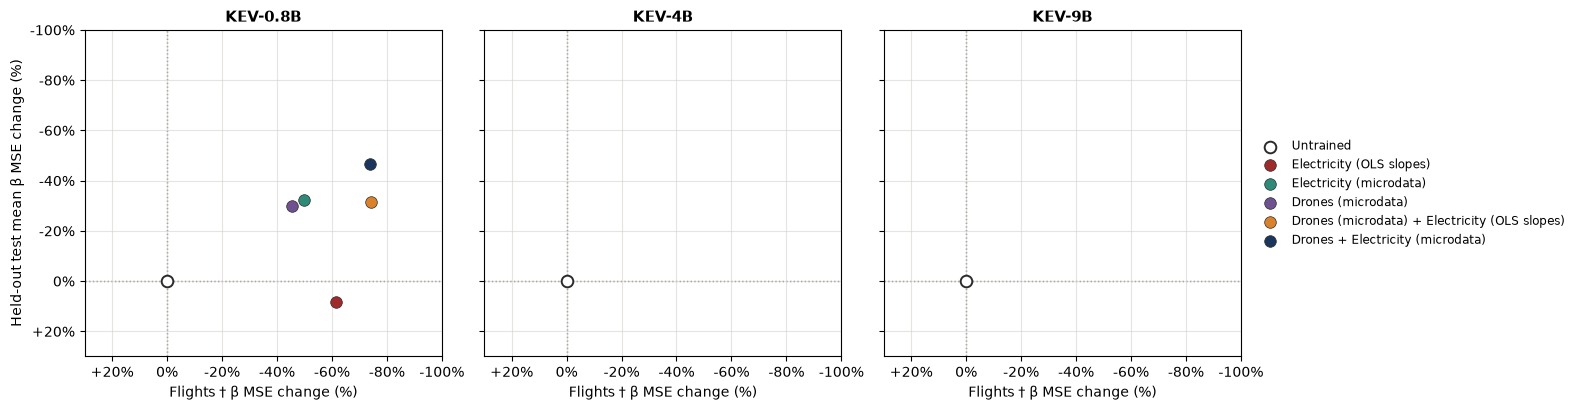

Note. Each point is one training regime. x-axis: Flights †; y-axis: mean of Food labels, Vaccines, Consumer rights, and AI & offshoring. Both axes show the percentage change in population β MSE versus the untrained model (open circle at the origin) and are reversed, so up and right are better. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). Missing points: runs or held-out test evaluations not finished yet.


In [5]:
OVERVIEW_MODELS = MODEL_SLUGS
OVERVIEW_SLUGS = (
    "row2_wu_table_anchored",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
OVERVIEW_STEP = {
    "row2_wu_table_anchored": "2",
    "row2b_wu_ce_oracle": "1, 2",
    "row3_berke_ce_only": "1, 3",
    "row4_hybrid_berke_ce_wu_table_anchored": "3",
    "row5_full_berke_wu_ce_oracle": "1, 3",
}
OVERVIEW_DATA_USED = {
    "row2_wu_table_anchored": ("", "✓", ""),
    "row2b_wu_ce_oracle": ("✓", "", ""),
    "row3_berke_ce_only": ("", "", "✓"),
    "row4_hybrid_berke_ce_wu_table_anchored": ("", "✓", "✓"),
    "row5_full_berke_wu_ce_oracle": ("✓", "", "✓"),
}
TEST_KEYS = ("grummon", "covid", "kantorowicz", "magistro")


def pct_change_vs_base(model_slug: str, slug: str, ds_key: str) -> float:
    sub = regimes_by_model[model_slug]
    base_value = float(sub.loc[BASE_SLUG, f"{ds_key}_mse"])
    value = float(sub.loc[slug, f"{ds_key}_mse"])
    return 100.0 * (value - base_value) / base_value


def test_mean_pct_change(model_slug: str, slug: str) -> float:
    """Mean over the four held-out test sets of the % change in β MSE vs. untrained."""
    changes = []
    for ds_key in TEST_KEYS:
        changes.append(pct_change_vs_base(model_slug, slug, ds_key))
    return float(np.mean(changes))


overview_rows = []
for slug in OVERVIEW_SLUGS:
    elec_micro, elec_slopes, drones_micro = OVERVIEW_DATA_USED[slug]
    row = {
        ("", "Trained on"): STORY_LABELS[slug],
        ("", "Step"): OVERVIEW_STEP[slug],
        ("Data used", "Electricity (microdata)"): elec_micro,
        ("Data used", "Electricity (OLS slopes)"): elec_slopes,
        ("Data used", "Drones (microdata)"): drones_micro,
    }
    for model_slug in OVERVIEW_MODELS:
        flights_change = pct_change_vs_base(model_slug, slug, "kriner")
        test_change = test_mean_pct_change(model_slug, slug)
        row[(MODEL_DISPLAY[model_slug], "Flights †")] = format_pct(flights_change)
        row[(MODEL_DISPLAY[model_slug], "Test mean")] = format_pct(test_change)
    overview_rows.append(row)

overview_df = pd.DataFrame(overview_rows)
overview_df.columns = pd.MultiIndex.from_tuples(overview_df.columns)
overview_df = overview_df.set_index([("", "Trained on")])
overview_df.index.name = "Trained on"
print_caption("Table 0b", "Overview of Training Regimes")
display(overview_df)
print_note(
    "Values are percentage changes in population β MSE versus the untrained model; negative is better. "
    "Test mean = mean of the changes on Food labels, Vaccines, Consumer rights, and AI & offshoring. "
    "Electricity (OLS slopes) trains on 8 published-specification OLS slopes from Wu (2025) with the KL anchor (α = 0.005); "
    "Electricity (microdata) trains on Wu's 18,591 respondent choices; Drones (microdata) trains on 36,297 respondent choices from Berke et al. (2023). "
    f"{ROLES_NOTE} NaN = run or held-out test evaluation not finished yet."
)

OVERVIEW_AXIS_LIMITS = (30.0, -100.0)
signed_pct_formatter = FuncFormatter(lambda v, _: "0%" if v == 0 else f"{v:+.0f}%")

print_caption("Figure 0", "Change in β MSE on Flights † Versus the Held-Out Test Sets")

fig, axes = plt.subplots(1, len(OVERVIEW_MODELS), figsize=(3.9 * len(OVERVIEW_MODELS) + 4.2, 4.2), sharex=True, sharey=True)
for ax, model_slug in zip(axes, OVERVIEW_MODELS):
    ax.axhline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    ax.axvline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    ax.scatter([0.0], [0.0], s=70, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[BASE_SLUG])
    for slug in OVERVIEW_SLUGS:
        x_value = pct_change_vs_base(model_slug, slug, "kriner")
        y_value = test_mean_pct_change(model_slug, slug)
        ax.scatter([x_value], [y_value], s=70, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])
    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Flights † β MSE change (%)")
    ax.xaxis.set_major_formatter(signed_pct_formatter)
    ax.yaxis.set_major_formatter(signed_pct_formatter)
    ax.grid(color=NEUTRALS["grid"], alpha=0.6)
    ax.set_xlim(OVERVIEW_AXIS_LIMITS)
    ax.set_ylim(OVERVIEW_AXIS_LIMITS)

axes[0].set_ylabel("Held-out test mean β MSE change (%)")
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note(
    "Each point is one training regime. x-axis: Flights †; y-axis: mean of Food labels, Vaccines, Consumer rights, and AI & offshoring. "
    "Both axes show the percentage change in population β MSE versus the untrained model (open circle at the origin) and are reversed, so up and right are better. "
    f"{ROLES_NOTE} Missing points: runs or held-out test evaluations not finished yet."
)

---
## Step 1 — Microdata Fine-Tuning Transfers to Unseen Domains (`Untrained` vs. `Electricity (microdata)`, `Drones (microdata)`, `Drones + Electricity (microdata)`)

In [6]:
STEP1_MODELS = MODEL_SLUGS
STEP1_SLUGS = (
    "row1_base_untrained",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row5_full_berke_wu_ce_oracle",
)

print_caption("Table 1", "Population β MSE After Microdata Fine-Tuning")
display(build_mse_styler(STEP1_MODELS, STEP1_SLUGS, STORY_COLUMNS))
print_note(
    "Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. "
    "Bold marks the lowest trained value per model and column when it improves on Untrained. "
    f"{ROLES_NOTE} NaN = run or held-out test evaluation not finished yet."
)

Table 1
Population β MSE After Microdata Fine-Tuning


Note. Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest trained value per model and column when it improves on Untrained. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run or held-out test evaluation not finished yet.


Figure 1
Microdata Fine-Tuning Across Benchmarks


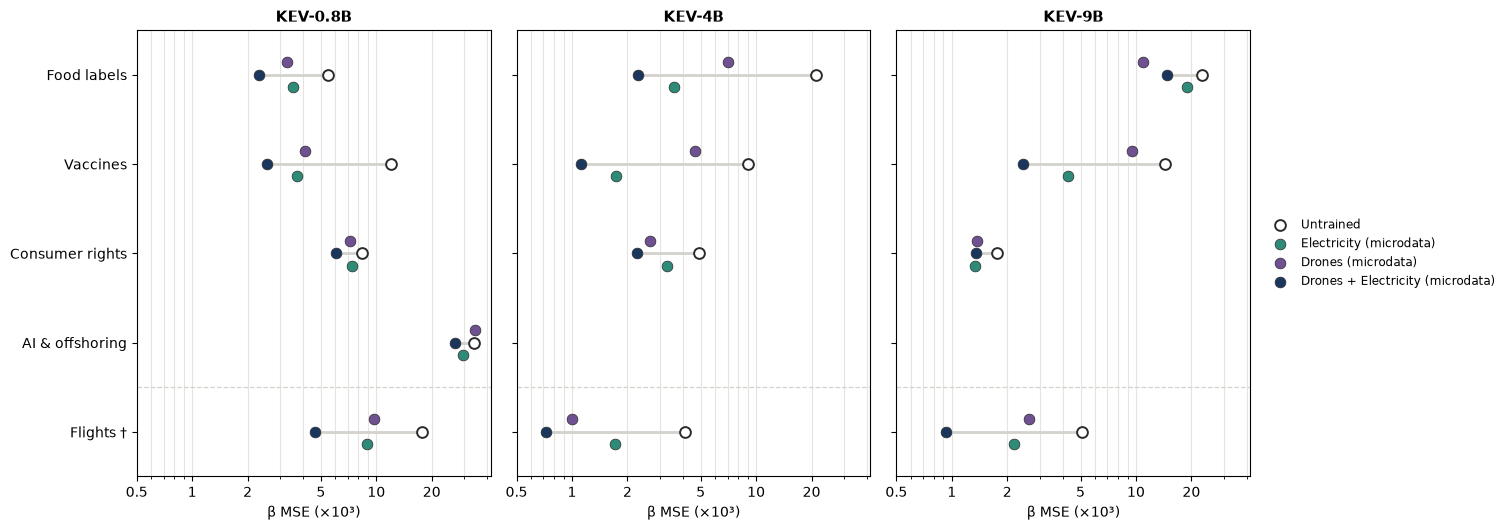

Note. Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins the untrained model to the combined-microdata reference, Drones + Electricity (microdata). The dashed horizontal line separates held-out test sets (above) from the validation set (below). Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). Missing points: runs or held-out test evaluations not finished yet.


In [7]:
print_caption("Figure 1", "Microdata Fine-Tuning Across Benchmarks")
plot_dot_panels(
    models=STEP1_MODELS,
    slugs=STEP1_SLUGS,
    datasets=STORY_COLUMNS,
    y_offsets={
        "row1_base_untrained": 0.0,
        "row2b_wu_ce_oracle": 0.14,
        "row3_berke_ce_only": -0.14,
        "row5_full_berke_wu_ce_oracle": 0.0,
    },
    x_ticks=(0.5, 1, 2, 5, 10, 20),
    reference_slug="row5_full_berke_wu_ce_oracle",
)
print_note(
    "Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a shared log scale; lower is better. "
    "The grey bar joins the untrained model to the combined-microdata reference, Drones + Electricity (microdata). "
    "The dashed horizontal line separates held-out test sets (above) from the validation set (below). "
    f"{ROLES_NOTE} Missing points: runs or held-out test evaluations not finished yet."
)

---
## Step 2 — Published OLS Slopes Teach the Study's Preferences (`Untrained` vs. `Electricity (OLS slopes)` vs. `Electricity (microdata)`)

In [8]:
STEP2_MODELS = MODEL_SLUGS
STEP2_SLUGS = (
    "row1_base_untrained",
    "row2_wu_table_anchored",
    "row2b_wu_ce_oracle",
)

print_caption("Table 2", "Electricity (OLS Slopes) Versus Electricity (Microdata)")
display(build_mse_styler(STEP2_MODELS, STEP2_SLUGS, STORY_COLUMNS))
print_note(
    "Electricity (OLS slopes) = 8 OLS slopes reproduced from Wu (2025)'s specification, trained with the population β-loss and the KL anchor (α = 0.005); respondent choices are withheld. "
    "Electricity (microdata) = Wu (2025)'s 18,591 respondent choices. "
    "Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. "
    "Bold marks the lowest trained value per model and column when it improves on Untrained. "
    f"{ROLES_NOTE} NaN = run or held-out test evaluation not finished yet."
)

Table 2
Electricity (OLS Slopes) Versus Electricity (Microdata)


Note. Electricity (OLS slopes) = 8 OLS slopes reproduced from Wu (2025)'s specification, trained with the population β-loss and the KL anchor (α = 0.005); respondent choices are withheld. Electricity (microdata) = Wu (2025)'s 18,591 respondent choices. Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest trained value per model and column when it improves on Untrained. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run or held-out test evaluation not finished yet.


Figure 2
Electricity (OLS Slopes) Versus Electricity (Microdata)


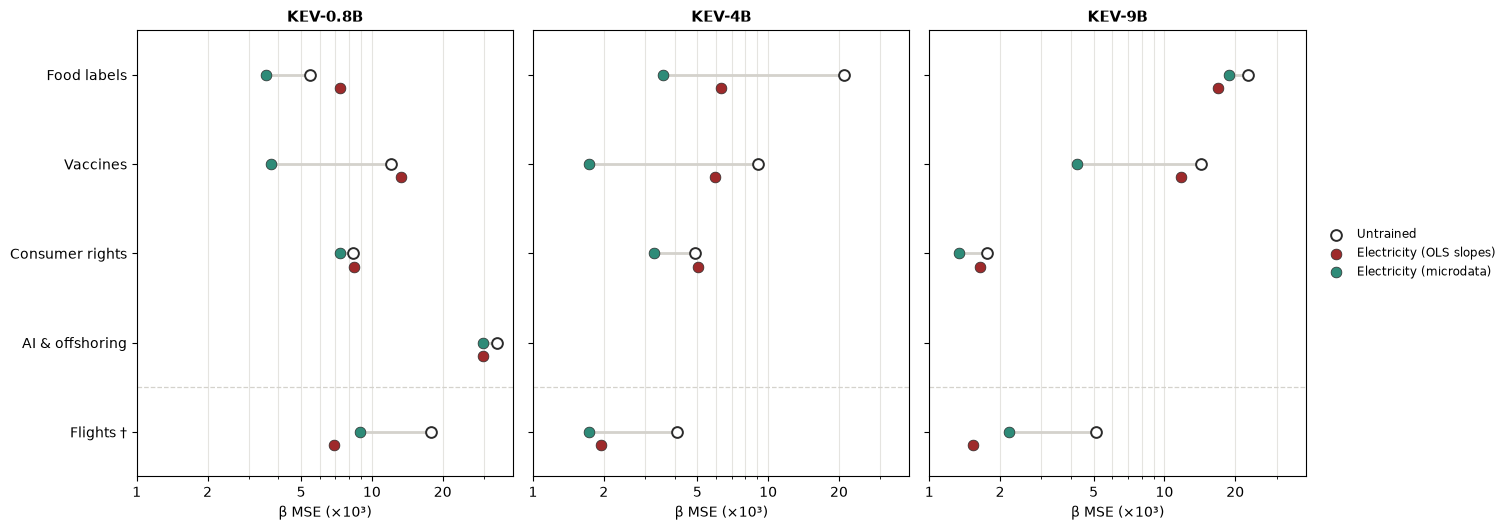

Note. Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins the untrained model to the microdata reference, Electricity (microdata). The dashed horizontal line separates held-out test sets (above) from the validation set (below). Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). Missing points: runs or held-out test evaluations not finished yet.


In [ ]:
print_caption("Figure 2", "Electricity (OLS Slopes) Versus Electricity (Microdata)")
plot_dot_panels(
    models=STEP2_MODELS,
    slugs=STEP2_SLUGS,
    datasets=STORY_COLUMNS,
    y_offsets={
        "row1_base_untrained": 0.0,
        "row2_wu_table_anchored": 0.15,
        "row2b_wu_ce_oracle": 0.0,
    },
    x_ticks=(1, 2, 5, 10, 20),
    reference_slug="row2b_wu_ce_oracle",
)
print_note(
    "Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a shared log scale; lower is better. "
    "The grey bar joins the untrained model to the microdata reference, Electricity (microdata). "
    "The dashed horizontal line separates held-out test sets (above) from the validation set (below). "
    f"{ROLES_NOTE} Missing points: runs or held-out test evaluations not finished yet."
)


### Step 2 Takeaway

Training on only the eight published-specification OLS slopes of Wu (2025) (`Electricity (OLS slopes)`) cuts population $\beta$ MSE on `Flights †`—which shares price and sustainability trade-offs with electricity plans—across all three model scales (`-61%` on `KEV-0.8B`, `-52%` on `KEV-4B`, and `-70%` on `KEV-9B`), matching or outperforming `18,591` respondent microdata choices (`Electricity (microdata)`). Because `Flights †` selects `best.pt`, the held-out test sets provide the stricter test of out-of-domain generalization. On `Food labels` and `Vaccines`, which share neither price nor energy attributes with `Electricity`, model scale separates what eight slopes alone can achieve: `KEV-4B` (`-70%`, `-35%`) and `KEV-9B` (`-26%`, `-18%`) still improve over `Untrained` on every benchmark, whereas the smallest model (`KEV-0.8B`) improves `Choice KL` (`Table A3`) but worsens $\beta$ MSE (`+34%` on `Food labels`, `+11%` on `Vaccines`). On the new held-out price-and-rights benchmark (`Consumer rights`, Kantorowicz-Reznichenko et al., 2026), `KEV-0.8B` already cuts `Price` $\beta$ MSE by `-15%` from the eight electricity slopes alone (Table 3b, vs. `-1%` under `Electricity (microdata)`) even though its overall 38-slope $\beta$ MSE stays near baseline (`+1%`); `KEV-4B` and `KEV-9B` evaluations on `Consumer rights` will populate automatically once their `test-best` runs finish. Eight aggregate slopes therefore transmit attribute-aligned preferences at every scale, while general calibration on distant domains requires either a larger backbone or respondent microdata—motivating the hybrid regime in Step 3, where pairing `Drones (microdata)` with `Electricity (OLS slopes)` removes the `KEV-0.8B` degradation on distant domains while cutting `Consumer rights` $\beta$ MSE by `-19%` (and preserving the full gain on `Flights †`).

---
## Step 3 — Combining Own Microdata With Another Study's OLS Slopes (`Untrained` vs. `Drones (microdata)` vs. `Drones (microdata) + Electricity (OLS slopes)` vs. `Drones + Electricity (microdata)`)

In [11]:
STEP3_MODELS = MODEL_SLUGS
STEP3_SLUGS = (
    "row1_base_untrained",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)

print_caption("Table 3", "Drones (Microdata) + Electricity (OLS Slopes) Versus Drones + Electricity (Microdata)")
display(build_mse_styler(STEP3_MODELS, STEP3_SLUGS, STORY_COLUMNS))
print_note(
    "Drones (microdata) + Electricity (OLS slopes) = 36,297 respondent choices from Berke et al. (2023) plus 8 reproduced OLS slopes from Wu (2025) with the KL anchor (α = 0.005). "
    "Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. "
    "Bold marks the lowest trained value per model and column when it improves on Untrained. "
    f"{ROLES_NOTE} NaN = run or held-out test evaluation not finished yet."
)

Table 3
Drones (Microdata) + Electricity (OLS Slopes) Versus Drones + Electricity (Microdata)


Note. Drones (microdata) + Electricity (OLS slopes) = 36,297 respondent choices from Berke et al. (2023) plus 8 reproduced OLS slopes from Wu (2025) with the KL anchor (α = 0.005). Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest trained value per model and column when it improves on Untrained. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run or held-out test evaluation not finished yet.


Figure 3
Drones (Microdata) + Electricity (OLS Slopes) Versus Drones + Electricity (Microdata)


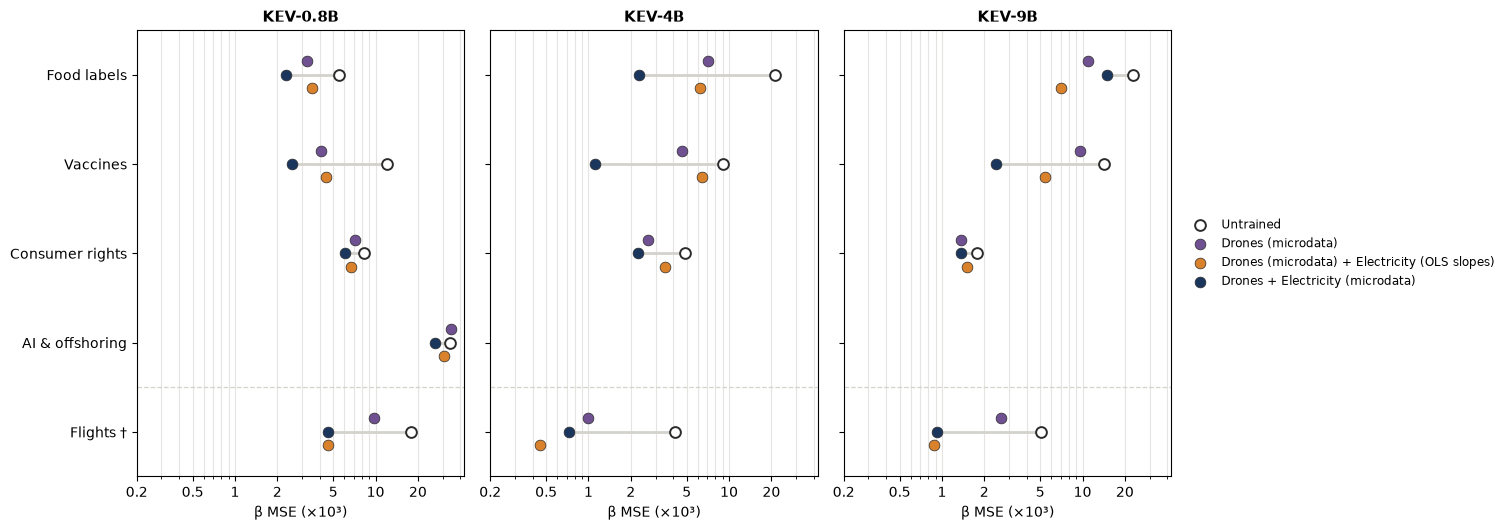

Note. Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins the untrained model to the combined-microdata reference, Drones + Electricity (microdata). The dashed horizontal line separates held-out test sets (above) from the validation set (below). Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). Missing points: runs or held-out test evaluations not finished yet.


In [12]:
print_caption("Figure 3", "Drones (Microdata) + Electricity (OLS Slopes) Versus Drones + Electricity (Microdata)")
plot_dot_panels(
    models=STEP3_MODELS,
    slugs=STEP3_SLUGS,
    datasets=STORY_COLUMNS,
    y_offsets={
        "row1_base_untrained": 0.0,
        "row3_berke_ce_only": -0.15,
        "row4_hybrid_berke_ce_wu_table_anchored": 0.15,
        "row5_full_berke_wu_ce_oracle": 0.0,
    },
    x_ticks=(0.2, 0.5, 1, 2, 5, 10, 20),
    reference_slug="row5_full_berke_wu_ce_oracle",
)
print_note(
    "Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a shared log scale; lower is better. "
    "The grey bar joins the untrained model to the combined-microdata reference, Drones + Electricity (microdata). "
    "The dashed horizontal line separates held-out test sets (above) from the validation set (below). "
    f"{ROLES_NOTE} Missing points: runs or held-out test evaluations not finished yet."
)

---
## Step 4 — Where the OLS Slopes Help: `Flights †` Slopes by Attribute (`Drones (microdata)` vs. `Drones (microdata) + Electricity (OLS slopes)` vs. `Drones + Electricity (microdata)`)

Figure 4
Flights † Slope Errors by Attribute


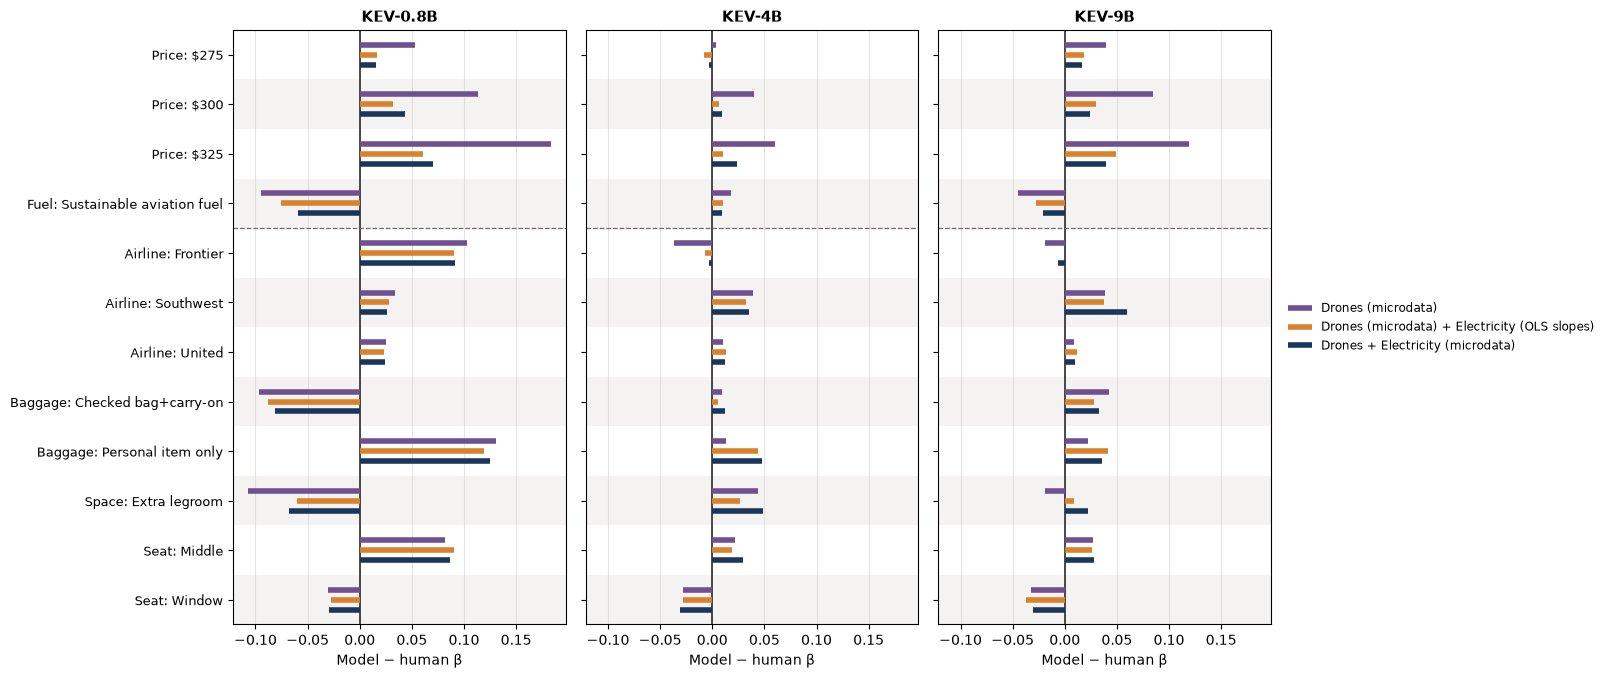

Note. Bars show model minus human population β for each Flights † (Goldfarb et al., 2026) attribute level; 0 means the model matches humans. Price and sustainable aviation fuel (closest to Electricity's bill and renewables attributes) are listed first above the dashed divider. Values are in Table A6. † Flights is the validation set and selects each run's checkpoint (best.pt). Empty panels or bars: runs not finished yet.
[EXCLUDE]


In [16]:
STEP4_MODELS = MODEL_SLUGS
STEP4_SLUGS = (
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
STEP4_Y_OFFSETS = {
    "row3_berke_ce_only": -0.2,
    "row4_hybrid_berke_ce_wu_table_anchored": 0.0,
    "row5_full_berke_wu_ce_oracle": 0.2,
}


def load_kriner_human_betas(model_slug: str) -> pd.Series:
    """Human Flights † slopes (the same for every run) from the first finished run of this model."""
    for slug in TRAINED_SLUGS:
        run_dir = find_run_dir(model_slug, slug)
        if run_is_finished(run_dir):
            _, betas = load_paper_run(run_dir).best_validation["kriner2026"]
            return betas["human_pop_beta"]
    raise FileNotFoundError(f"No finished run for {model_slug} in {REGIME_RUN_ROOTS}")


def load_kriner_betas(model_slug: str, slug: str, human_betas: pd.Series) -> pd.DataFrame:
    """Per-term Flights † population slopes at the run's best.pt; model slopes are NaN if the run is not finished yet."""
    run_dir = find_run_dir(model_slug, slug)
    if not run_is_finished(run_dir):
        return pd.DataFrame({"human_pop_beta": human_betas, "model_pop_beta": np.nan})
    _, betas = load_paper_run(run_dir).best_validation["kriner2026"]
    if list(betas.index) != list(human_betas.index):
        raise ValueError(f"{model_slug}/{slug}: Flights terms {list(betas.index)} != {list(human_betas.index)}")
    return betas[["human_pop_beta", "model_pop_beta"]]


kriner_betas_by_model = {}
for model_slug in STEP4_MODELS:
    kriner_betas_by_model[model_slug] = {}
    human_betas = load_kriner_human_betas(model_slug)
    for slug in STEP4_SLUGS:
        kriner_betas_by_model[model_slug][slug] = load_kriner_betas(model_slug, slug, human_betas)

all_kriner_terms = list(kriner_betas_by_model[STEP4_MODELS[0]][STEP4_SLUGS[0]].index)
price_terms = [term for term in all_kriner_terms if term.startswith("Price:")]
fuel_terms = [term for term in all_kriner_terms if term.startswith("Fuel:")]
if len(price_terms) == 0:
    raise ValueError(f"No price terms in Flights †: {all_kriner_terms}")
if len(fuel_terms) == 0:
    raise ValueError(f"No fuel terms in Flights †: {all_kriner_terms}")
transferred_terms = price_terms + fuel_terms
other_terms = [term for term in all_kriner_terms if term not in transferred_terms]
kriner_terms = transferred_terms + other_terms
TRANSFERRED_DIVIDER_Y = len(transferred_terms) - 0.5
y_positions = np.arange(len(kriner_terms))

print_caption("Figure 4", "Flights † Slope Errors by Attribute")
fig, axes = plt.subplots(1, len(STEP4_MODELS), figsize=(3.8 * len(STEP4_MODELS) + 4.8, 0.44 * len(kriner_terms) + 1.6), sharey=True, sharex=True)
for ax, model_slug in zip(axes, STEP4_MODELS):
    ax.axvline(0.0, color=NEUTRALS["text"], linewidth=1.2, zorder=2)
    ax.axhline(TRANSFERRED_DIVIDER_Y, color=NEUTRALS["ref_line"], linestyle="--", linewidth=0.9, zorder=2)
    for y in y_positions:
        if y % 2 == 1:
            ax.axhspan(y - 0.5, y + 0.5, color=NEUTRALS["grid"], alpha=0.25, zorder=0, linewidth=0)
    for slug in STEP4_SLUGS:
        betas = kriner_betas_by_model[model_slug][slug].loc[kriner_terms]
        errors = (betas["model_pop_beta"] - betas["human_pop_beta"]).to_numpy(dtype=float)
        y_shifted = y_positions + STEP4_Y_OFFSETS[slug]
        ax.hlines(y_shifted, 0.0, errors, color=STORY_COLORS[slug], linewidth=4.0, zorder=3, label=STORY_LABELS[slug])
    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Model − human β")
    ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6)

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(kriner_terms, fontsize=9)
axes[0].set_ylim(-0.5, len(kriner_terms) - 0.5)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note(
    "Bars show model minus human population β for each Flights † (Goldfarb et al., 2026) attribute level; 0 means the model matches humans. "
    "Price and sustainable aviation fuel (closest to Electricity's bill and renewables attributes) are listed first above the dashed divider. "
    "Values are in Table A6. † Flights is the validation set and selects each run's checkpoint (best.pt). Empty panels or bars: runs not finished yet."
)
print('[EXCLUDE]')

Figure 5
Flights † Population β by Attribute: Humans and Models


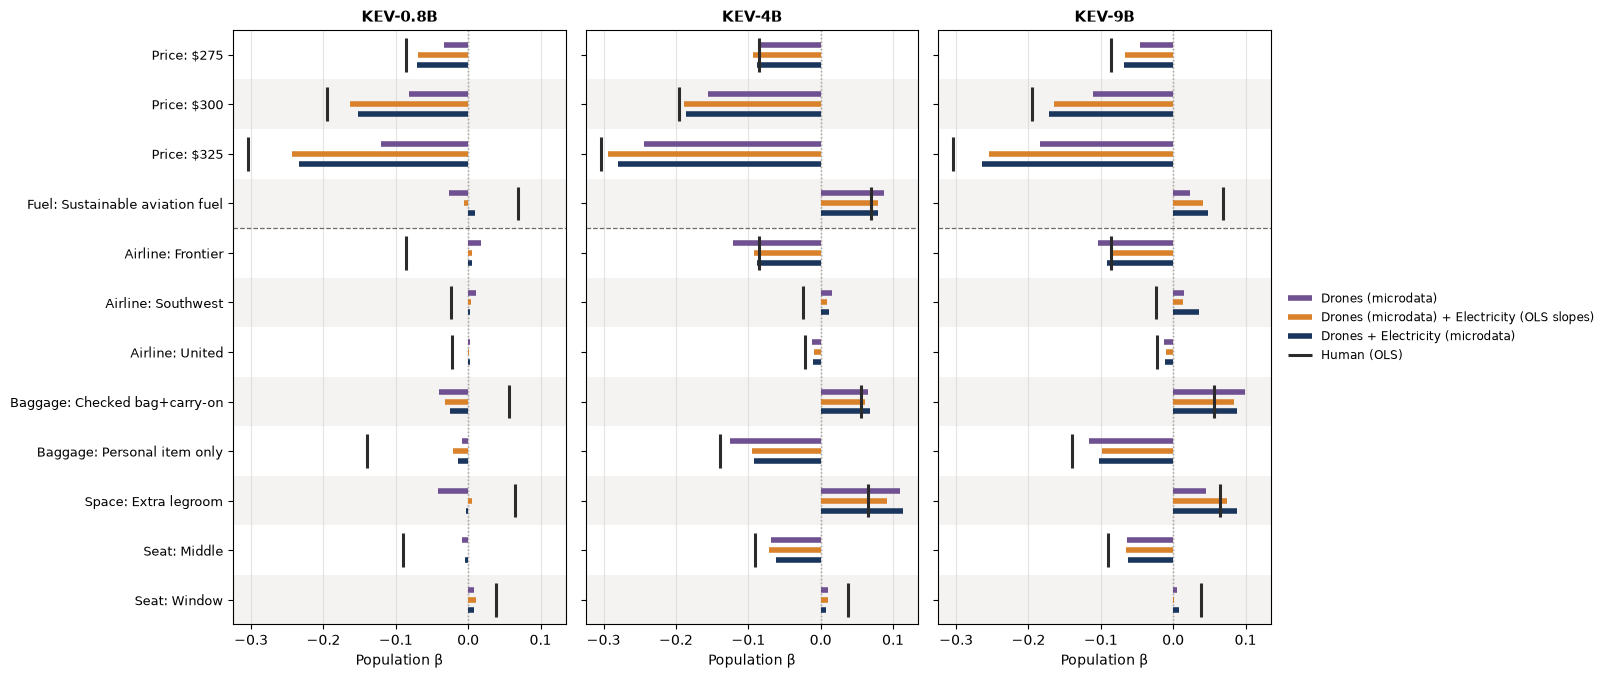

Note. Bars show each model's population β for each Flights † (Goldfarb et al., 2026) attribute level; the black tick marks the human OLS slope on the same row. A bar that ends at the tick matches humans. Price and sustainable aviation fuel are listed first above the dashed divider. Figure 4 shows the same values as model minus human; numbers are in Table A6. † Flights is the validation set and selects each run's checkpoint (best.pt). Empty panels or bars: runs not finished yet.
[include]


In [17]:
HUMAN_TICK_HALF_HEIGHT = 0.34

print_caption("Figure 5", "Flights † Population β by Attribute: Humans and Models")
fig, axes = plt.subplots(1, len(STEP4_MODELS), figsize=(3.8 * len(STEP4_MODELS) + 4.8, 0.44 * len(kriner_terms) + 1.6), sharey=True, sharex=True)
for ax, model_slug in zip(axes, STEP4_MODELS):
    ax.axvline(0.0, color=NEUTRALS["ref_line"], linewidth=1.0, linestyle=":", zorder=1)
    ax.axhline(TRANSFERRED_DIVIDER_Y, color=NEUTRALS["ref_line"], linestyle="--", linewidth=0.9, zorder=2)
    for y in y_positions:
        if y % 2 == 1:
            ax.axhspan(y - 0.5, y + 0.5, color=NEUTRALS["grid"], alpha=0.25, zorder=0, linewidth=0)

    for slug in STEP4_SLUGS:
        betas = kriner_betas_by_model[model_slug][slug].loc[kriner_terms]
        model_values = betas["model_pop_beta"].to_numpy(dtype=float)
        y_shifted = y_positions + STEP4_Y_OFFSETS[slug]
        ax.hlines(y_shifted, 0.0, model_values, color=STORY_COLORS[slug], linewidth=4.0, zorder=3, label=STORY_LABELS[slug])

    human_values = kriner_betas_by_model[model_slug][STEP4_SLUGS[0]].loc[kriner_terms, "human_pop_beta"].to_numpy(dtype=float)
    ax.vlines(human_values, y_positions - HUMAN_TICK_HALF_HEIGHT, y_positions + HUMAN_TICK_HALF_HEIGHT, color=NEUTRALS["text"], linewidth=2.2, zorder=4, label="Human (OLS)")

    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Population β")
    ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6)

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(kriner_terms, fontsize=9)
axes[0].set_ylim(-0.5, len(kriner_terms) - 0.5)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note(
    "Bars show each model's population β for each Flights † (Goldfarb et al., 2026) attribute level; the black tick marks the human OLS slope on the same row. "
    "A bar that ends at the tick matches humans. Price and sustainable aviation fuel are listed first above the dashed divider. "
    "Figure 4 shows the same values as model minus human; numbers are in Table A6. † Flights is the validation set and selects each run's checkpoint (best.pt). Empty panels or bars: runs not finished yet."
)
print('[include]')

---
### Held-Out Attribute Transfer: `Consumer rights` (Price vs. Non-Price Attributes)

Table 3b
Consumer Rights Population β MSE (×10³) by Attribute Group and Product


Note. Held-out Consumer rights benchmark (Kantorowicz-Reznichenko et al., 2026; 38 AMCEs across 19 laptop and 19 laundry-machine slopes). Values are population β MSE ×10³, with percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest trained value per model and column when it improves on Untrained. Price (4) = laptop and laundry price slopes; Brand (6) = brand dummies; Product specs (12) = RAM, storage, processor, depth, noise, and load capacity; Contractual rights (16) = warranty, privacy, liability, and conflict resolution. NaN = held-out Consumer rights evaluation not finished yet.
Figure 5b
Consumer Rights Population β MSE by Attribute Group: Price Versus Non-Price Attributes


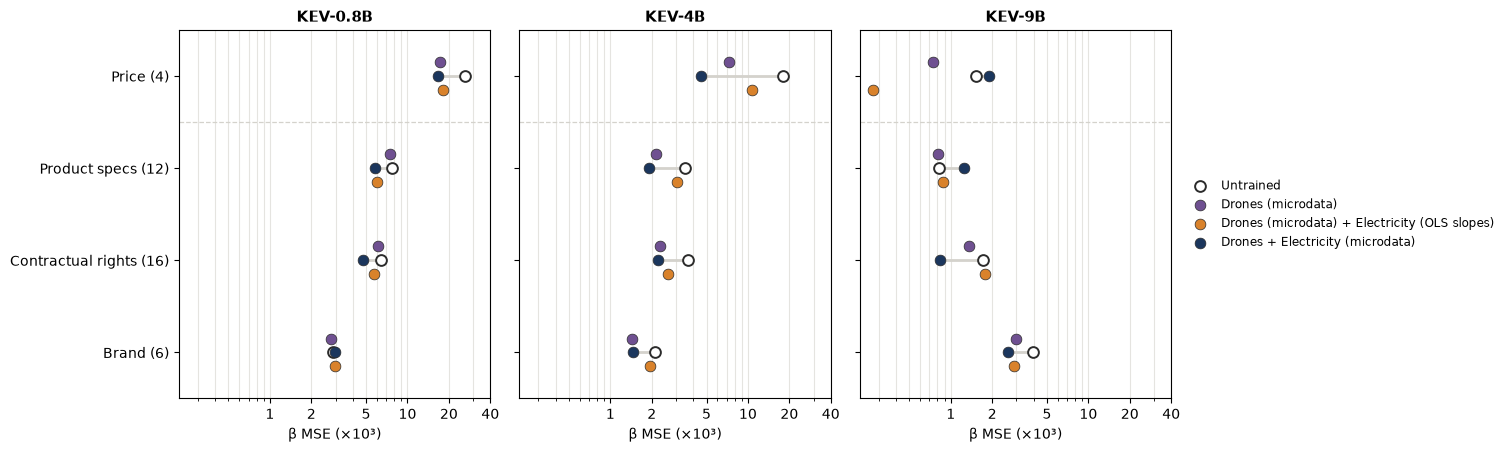

Note. Open circles are the untrained model; filled circles are fine-tuned runs on the held-out Consumer rights test set (Kantorowicz-Reznichenko et al., 2026). Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Drones + Electricity (microdata). The dashed horizontal line separates Price (above, directly aligned with Electricity's bill attribute) from non-price attribute groups (below). Missing points: held-out Consumer rights evaluations not finished yet.


In [18]:
K26_ATTR_GROUPS = (
    ("price", "Price (4)"),
    ("brand", "Brand (6)"),
    ("specs", "Product specs (12)"),
    ("rights", "Contractual rights (16)"),
)
K26_BREAKDOWN_COLUMNS = (
    ("all", "All (38)"),
    ("price", "Price (4)"),
    ("brand", "Brand (6)"),
    ("specs", "Product specs (12)"),
    ("rights", "Contractual rights (16)"),
    ("computers", "Laptops (19)"),
    ("laundry", "Laundry (19)"),
)
K26_TABLE_SLUGS = (
    "row1_base_untrained",
    "row2_wu_table_anchored",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
K26_SPECS_ATTRS = {"RAM", "Storage", "Processor", "Depth", "Noise", "Load capacity"}
K26_RIGHTS_ATTRS = {"Warranty", "Privacy", "Liability", "Conflict resolution"}


def kantorowicz_attr_group(term: str) -> str:
    _, rest = term.split(" | ", 1)
    attr = rest.split(":", 1)[0]
    if attr == "Price":
        return "price"
    if attr == "Brand":
        return "brand"
    if attr in K26_SPECS_ATTRS:
        return "specs"
    if attr in K26_RIGHTS_ATTRS:
        return "rights"
    raise ValueError(f"Unrecognized Consumer rights attribute in term {term!r}")


def kantorowicz_breakdown_metrics(beta_df: pd.DataFrame) -> dict[str, float]:
    sq_err = (beta_df["model_pop_beta"] - beta_df["human_pop_beta"]).pow(2)
    groups = pd.Series([kantorowicz_attr_group(t) for t in beta_df.index], index=beta_df.index)
    out = {"all": float(sq_err.mean())}
    for g_key, _ in K26_ATTR_GROUPS:
        mask = groups == g_key
        if not mask.any():
            raise ValueError(f"No terms matched Consumer rights group {g_key!r}")
        out[g_key] = float(sq_err.loc[mask].mean())
    for prod_key, model_name in (("computers", "kantorowicz2026/computers"), ("laundry", "kantorowicz2026/laundry")):
        mask = beta_df["model"] == model_name
        if not mask.any():
            raise ValueError(f"No terms matched Consumer rights model {model_name!r}")
        out[prod_key] = float(sq_err.loc[mask].mean())
    return out


k26_breakdown_frames = []
for model_slug in STEP4_MODELS:
    betas_by_slug = kantorowicz_betas_by_model[model_slug]
    rows = []
    for slug in K26_TABLE_SLUGS:
        if slug in betas_by_slug:
            metrics = kantorowicz_breakdown_metrics(betas_by_slug[slug])
        else:
            metrics = {col_key: np.nan for col_key, _ in K26_BREAKDOWN_COLUMNS}
        rows.append({col_label: metrics[col_key] for col_key, col_label in K26_BREAKDOWN_COLUMNS})
    frame = pd.DataFrame(rows)
    frame.index = pd.MultiIndex.from_tuples(
        [(MODEL_DISPLAY[model_slug], slug) for slug in K26_TABLE_SLUGS],
        names=["Model", "Trained on"],
    )
    k26_breakdown_frames.append(frame)

k26_breakdown_values = pd.concat(k26_breakdown_frames)
k26_breakdown_text = pd.DataFrame("", index=k26_breakdown_values.index, columns=k26_breakdown_values.columns)
for model_name, slug in k26_breakdown_values.index:
    for col in k26_breakdown_values.columns:
        val = float(k26_breakdown_values.loc[(model_name, slug), col])
        base_val = float(k26_breakdown_values.loc[(model_name, BASE_SLUG), col])
        k26_breakdown_text.loc[(model_name, slug), col] = format_mse_cell(val, base_val, slug)

k26_breakdown_css = relabel_rows(best_cell_css(k26_breakdown_values))
print_caption("Table 3b", "Consumer Rights Population β MSE (×10³) by Attribute Group and Product")
display(relabel_rows(k26_breakdown_text).style.apply(lambda _df: k26_breakdown_css, axis=None))
print_note(
    "Held-out Consumer rights benchmark (Kantorowicz-Reznichenko et al., 2026; 38 AMCEs across 19 laptop and 19 laundry-machine slopes). "
    "Values are population β MSE ×10³, with percentage change versus the untrained model in parentheses; lower is better. "
    "Bold marks the lowest trained value per model and column when it improves on Untrained. "
    "Price (4) = laptop and laundry price slopes; Brand (6) = brand dummies; Product specs (12) = RAM, storage, processor, depth, noise, and load capacity; "
    "Contractual rights (16) = warranty, privacy, liability, and conflict resolution. NaN = held-out Consumer rights evaluation not finished yet."
)

# Figure 5b: Attribute-group dot panels (Price above the dashed divider vs. non-price attribute groups below)
K26_PLOT_SLUGS = (
    "row1_base_untrained",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
K26_PLOT_Y_OFFSETS = {
    "row1_base_untrained": 0.0,
    "row3_berke_ce_only": -0.15,
    "row4_hybrid_berke_ce_wu_table_anchored": 0.15,
    "row5_full_berke_wu_ce_oracle": 0.0,
}
K26_PLOT_GROUPS = (
    "Price (4)",
    "Product specs (12)",
    "Contractual rights (16)",
    "Brand (6)",
)

print_caption("Figure 5b", "Consumer Rights Population β MSE by Attribute Group: Price Versus Non-Price Attributes")
fig, axes = plt.subplots(
    1,
    len(STEP4_MODELS),
    figsize=(3.6 * len(STEP4_MODELS) + 4.4, 0.78 * len(K26_PLOT_GROUPS) + 1.5),
    sharex=True,
    sharey=True,
    squeeze=False,
)
axes = axes[0]
k26_y_positions = np.arange(len(K26_PLOT_GROUPS))
k26_x_ticks = (1, 2, 5, 10, 20, 40)

for ax, model_slug in zip(axes, STEP4_MODELS):
    model_block = k26_breakdown_values.xs(MODEL_DISPLAY[model_slug], level="Model")
    ax.axhline(0.5, color=NEUTRALS["grid"], linestyle="--", linewidth=0.9, zorder=0)
    for y, col_label in zip(k26_y_positions, K26_PLOT_GROUPS):
        base_val = float(model_block.loc[BASE_SLUG, col_label]) * MSE_SCALE
        end_val = float(model_block.loc["row5_full_berke_wu_ce_oracle", col_label]) * MSE_SCALE
        if not np.isnan(base_val) and not np.isnan(end_val):
            ax.plot([end_val, base_val], [y, y], color=NEUTRALS["grid"], linewidth=2.0, zorder=1)
    for slug in K26_PLOT_SLUGS:
        vals = [float(model_block.loc[slug, col_label]) * MSE_SCALE for col_label in K26_PLOT_GROUPS]
        y_shifted = k26_y_positions + K26_PLOT_Y_OFFSETS[slug]
        if slug == BASE_SLUG:
            ax.scatter(vals, y_shifted, s=60, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[slug])
        else:
            ax.scatter(vals, y_shifted, s=60, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])
    ax.set_xscale("log")
    ax.set_xticks(k26_x_ticks)
    ax.set_xticklabels([f"{t:g}" for t in k26_x_ticks])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("β MSE (×10³)")
    ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6, which="both")

axes[0].set_yticks(k26_y_positions)
axes[0].set_yticklabels(K26_PLOT_GROUPS)
axes[0].set_ylim(-0.5, len(K26_PLOT_GROUPS) - 0.5)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note(
    "Open circles are the untrained model; filled circles are fine-tuned runs on the held-out Consumer rights test set (Kantorowicz-Reznichenko et al., 2026). "
    "Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Drones + Electricity (microdata). "
    "The dashed horizontal line separates Price (above, directly aligned with Electricity's bill attribute) from non-price attribute groups (below). "
    "Missing points: held-out Consumer rights evaluations not finished yet."
)

---
### Held-Out Attribute Transfer: `AI & offshoring` (Price vs. Job-Change Attributes)

Table 3c
AI & Offshoring Population β MSE (×10³) by Attribute Group and Country × Arm


Note. Held-out AI & offshoring benchmark (Magistro et al., 2025; 32 AMCEs across 4 country × arm regressions of 8 slopes each). Values are population β MSE ×10³, with percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest trained value per model and column when it improves on Untrained. Price (8) = smartphone price slopes; Factory jobs (8), Customer service jobs (8), and Data science jobs (8) = job-change slopes. NaN = held-out AI & offshoring evaluation not finished yet.
Figure 5c
AI & Offshoring Population β MSE by Attribute Group: Price Versus Job-Change Attributes


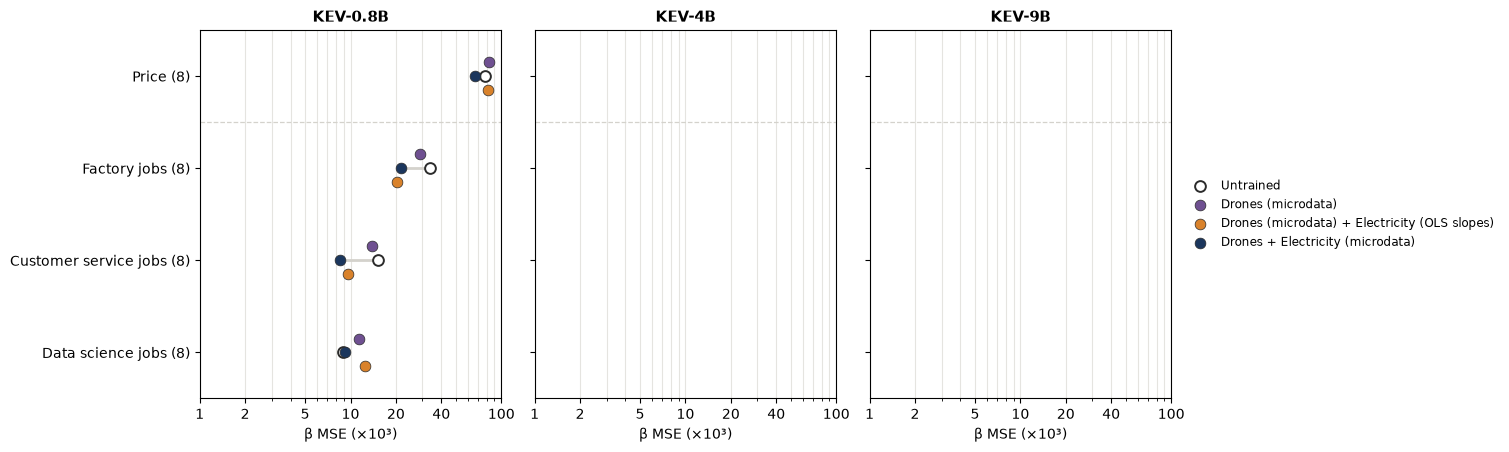

Note. Open circles are the untrained model; filled circles are fine-tuned runs on the held-out AI & offshoring test set (Magistro et al., 2025). Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Drones + Electricity (microdata). The dashed horizontal line separates Price (above, directly aligned with Electricity's bill attribute) from job-change attribute groups (below). Missing points: held-out AI & offshoring evaluations not finished yet.


In [19]:
M25_ATTR_GROUPS = (
    ("price", "Price (8)"),
    ("factory", "Factory jobs (8)"),
    ("service", "Customer service jobs (8)"),
    ("datasci", "Data science jobs (8)"),
)
M25_BREAKDOWN_COLUMNS = (
    ("all", "All (32)"),
    ("price", "Price (8)"),
    ("factory", "Factory jobs (8)"),
    ("service", "Customer service jobs (8)"),
    ("datasci", "Data science jobs (8)"),
    ("us_ai", "US AI (8)"),
    ("us_offshoring", "US Offshoring (8)"),
    ("ca_ai", "CA AI (8)"),
    ("ca_offshoring", "CA Offshoring (8)"),
)
M25_TABLE_SLUGS = K26_TABLE_SLUGS


def magistro_attr_group(term: str) -> str:
    _, rest = term.split(" | ", 1)
    attr = rest.split(":", 1)[0]
    if attr == "Price":
        return "price"
    if attr == "Factory jobs":
        return "factory"
    if attr == "Customer service jobs":
        return "service"
    if attr == "Data science jobs":
        return "datasci"
    raise ValueError(f"Unrecognized AI & offshoring attribute in term {term!r}")


def magistro_breakdown_metrics(beta_df: pd.DataFrame) -> dict[str, float]:
    sq_err = (beta_df["model_pop_beta"] - beta_df["human_pop_beta"]).pow(2)
    groups = pd.Series([magistro_attr_group(t) for t in beta_df.index], index=beta_df.index)
    out = {"all": float(sq_err.mean())}
    for g_key, _ in M25_ATTR_GROUPS:
        mask = groups == g_key
        if not mask.any():
            raise ValueError(f"No terms matched AI & offshoring group {g_key!r}")
        out[g_key] = float(sq_err.loc[mask].mean())
    for sub_key in ("us_ai", "us_offshoring", "ca_ai", "ca_offshoring"):
        model_name = f"magistro2025/{sub_key}"
        mask = beta_df["model"] == model_name
        if not mask.any():
            raise ValueError(f"No terms matched AI & offshoring model {model_name!r}")
        out[sub_key] = float(sq_err.loc[mask].mean())
    return out


m25_breakdown_frames = []
for model_slug in STEP4_MODELS:
    betas_by_slug = magistro_betas_by_model[model_slug]
    rows = []
    for slug in M25_TABLE_SLUGS:
        if slug in betas_by_slug:
            metrics = magistro_breakdown_metrics(betas_by_slug[slug])
        else:
            metrics = {col_key: np.nan for col_key, _ in M25_BREAKDOWN_COLUMNS}
        rows.append({col_label: metrics[col_key] for col_key, col_label in M25_BREAKDOWN_COLUMNS})
    frame = pd.DataFrame(rows)
    frame.index = pd.MultiIndex.from_tuples(
        [(MODEL_DISPLAY[model_slug], slug) for slug in M25_TABLE_SLUGS],
        names=["Model", "Trained on"],
    )
    m25_breakdown_frames.append(frame)

m25_breakdown_values = pd.concat(m25_breakdown_frames)
m25_breakdown_text = pd.DataFrame("", index=m25_breakdown_values.index, columns=m25_breakdown_values.columns)
for model_name, slug in m25_breakdown_values.index:
    for col in m25_breakdown_values.columns:
        val = float(m25_breakdown_values.loc[(model_name, slug), col])
        base_val = float(m25_breakdown_values.loc[(model_name, BASE_SLUG), col])
        m25_breakdown_text.loc[(model_name, slug), col] = format_mse_cell(val, base_val, slug)

m25_breakdown_css = relabel_rows(best_cell_css(m25_breakdown_values))
print_caption("Table 3c", "AI & Offshoring Population β MSE (×10³) by Attribute Group and Country × Arm")
display(relabel_rows(m25_breakdown_text).style.apply(lambda _df: m25_breakdown_css, axis=None))
print_note(
    "Held-out AI & offshoring benchmark (Magistro et al., 2025; 32 AMCEs across 4 country × arm regressions of 8 slopes each). "
    "Values are population β MSE ×10³, with percentage change versus the untrained model in parentheses; lower is better. "
    "Bold marks the lowest trained value per model and column when it improves on Untrained. "
    "Price (8) = smartphone price slopes; Factory jobs (8), Customer service jobs (8), and Data science jobs (8) = job-change slopes. "
    "NaN = held-out AI & offshoring evaluation not finished yet."
)

M25_PLOT_GROUPS = (
    "Price (8)",
    "Factory jobs (8)",
    "Customer service jobs (8)",
    "Data science jobs (8)",
)

if not m25_breakdown_values[list(M25_PLOT_GROUPS)].notna().any().any():
    print("Figure 5c pending: run 04-test-best-*.ipynb to populate magistro2025 in test_best/.")
else:
    print_caption("Figure 5c", "AI & Offshoring Population β MSE by Attribute Group: Price Versus Job-Change Attributes")
    fig, axes = plt.subplots(

        1,
        len(STEP4_MODELS),
        figsize=(3.6 * len(STEP4_MODELS) + 4.4, 0.78 * len(M25_PLOT_GROUPS) + 1.5),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    axes = axes[0]
    m25_y_positions = np.arange(len(M25_PLOT_GROUPS))
    m25_x_ticks = (1, 2, 5, 10, 20, 40, 100)

    for ax, model_slug in zip(axes, STEP4_MODELS):
        model_block = m25_breakdown_values.xs(MODEL_DISPLAY[model_slug], level="Model")
        ax.axhline(0.5, color=NEUTRALS["grid"], linestyle="--", linewidth=0.9, zorder=0)
        for y, col_label in zip(m25_y_positions, M25_PLOT_GROUPS):
            base_val = float(model_block.loc[BASE_SLUG, col_label]) * MSE_SCALE
            end_val = float(model_block.loc["row5_full_berke_wu_ce_oracle", col_label]) * MSE_SCALE
            if not np.isnan(base_val) and not np.isnan(end_val):
                ax.plot([end_val, base_val], [y, y], color=NEUTRALS["grid"], linewidth=2.0, zorder=1)
        for slug in K26_PLOT_SLUGS:
            vals = [float(model_block.loc[slug, col_label]) * MSE_SCALE for col_label in M25_PLOT_GROUPS]
            y_shifted = m25_y_positions + K26_PLOT_Y_OFFSETS[slug]
            if slug == BASE_SLUG:
                ax.scatter(vals, y_shifted, s=60, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[slug])
            else:
                ax.scatter(vals, y_shifted, s=60, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])
        ax.set_xscale("log")
        ax.set_xticks(m25_x_ticks)
        ax.set_xticklabels([f"{t:g}" for t in m25_x_ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
        ax.set_xlabel("β MSE (×10³)")
        ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6, which="both")

    axes[0].set_yticks(m25_y_positions)
    axes[0].set_yticklabels(M25_PLOT_GROUPS)
    axes[0].set_ylim(-0.5, len(M25_PLOT_GROUPS) - 0.5)
    axes[0].invert_yaxis()
    axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.tight_layout()
    plt.show()
    print_note(
        "Open circles are the untrained model; filled circles are fine-tuned runs on the held-out AI & offshoring test set (Magistro et al., 2025). "
        "Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Drones + Electricity (microdata). "
        "The dashed horizontal line separates Price (above, directly aligned with Electricity's bill attribute) from job-change attribute groups (below). "
        "Missing points: held-out AI & offshoring evaluations not finished yet."
    )

---
## Ablation — The KL Anchor (α = 0.005 vs. α = 0; α Sweep)

In [20]:
ABLATION_MODELS = MODEL_SLUGS
ABLATION_PAIRS = (
    ("a", "Electricity (OLS Slopes) With and Without the KL Anchor", "row2_wu_table_anchored", "row2_ablation_wu_table_no_kl"),
    ("b", "Drones (Microdata) + Electricity (OLS Slopes) With and Without the KL Anchor", "row4_hybrid_berke_ce_wu_table_anchored", "row4_hybrid_berke_ce_wu_table_no_kl"),
)
# The anchor is a design choice, so it is judged on the validation set alone; the held-out test sets stay out of it
ABLATION_COLUMNS = (("kriner", "Flights †"),)
ABLATION_ROLES_NOTE = (
    "† Flights (Goldfarb et al., 2026) is the validation set: it selects each run's checkpoint (best.pt) and is the only data set used to judge the anchor. "
    "The held-out test sets (Food labels, Grummon et al., 2025; Vaccines, Kreps et al., 2020; Consumer rights, Kantorowicz-Reznichenko et al., 2026; AI & offshoring, Magistro et al., 2025) are left out of this ablation so that they do not inform the method."
)

for letter, title, anchored_slug, no_anchor_slug in ABLATION_PAIRS:
    print_caption(f"Table 4{letter}", title)
    display(build_mse_styler(ABLATION_MODELS, (BASE_SLUG, anchored_slug, no_anchor_slug), ABLATION_COLUMNS))
    print_note(
        "With anchor = KL(p₀‖p_θ) on Electricity (Wu, 2025) tasks with weight α = 0.005; no anchor = α = 0. "
        "Values are population β MSE ×10³ at best.pt, with the percentage change versus the untrained model in parentheses; lower is better. "
        f"Bold marks the lower of the two runs per model when it improves on Untrained. {ABLATION_ROLES_NOTE} NaN = run not finished yet."
    )

Table 4a
Electricity (OLS Slopes) With and Without the KL Anchor


Note. With anchor = KL(p₀‖p_θ) on Electricity (Wu, 2025) tasks with weight α = 0.005; no anchor = α = 0. Values are population β MSE ×10³ at best.pt, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lower of the two runs per model when it improves on Untrained. † Flights (Goldfarb et al., 2026) is the validation set: it selects each run's checkpoint (best.pt) and is the only data set used to judge the anchor. The held-out test sets (Food labels, Grummon et al., 2025; Vaccines, Kreps et al., 2020; Consumer rights, Kantorowicz-Reznichenko et al., 2026; AI & offshoring, Magistro et al., 2025) are left out of this ablation so that they do not inform the method. NaN = run not finished yet.
Table 4b
Drones (Microdata) + Electricity (OLS Slopes) With and Without the KL Anchor


Note. With anchor = KL(p₀‖p_θ) on Electricity (Wu, 2025) tasks with weight α = 0.005; no anchor = α = 0. Values are population β MSE ×10³ at best.pt, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lower of the two runs per model when it improves on Untrained. † Flights (Goldfarb et al., 2026) is the validation set: it selects each run's checkpoint (best.pt) and is the only data set used to judge the anchor. The held-out test sets (Food labels, Grummon et al., 2025; Vaccines, Kreps et al., 2020; Consumer rights, Kantorowicz-Reznichenko et al., 2026; AI & offshoring, Magistro et al., 2025) are left out of this ablation so that they do not inform the method. NaN = run not finished yet.


Figure 6
Flights † Over Training: Electricity (OLS Slopes) With and Without the KL Anchor


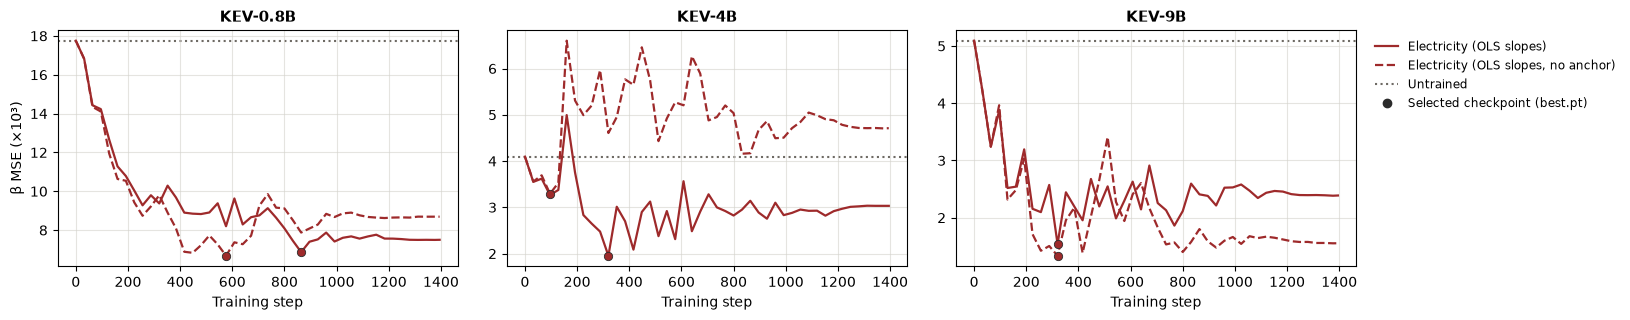

Note. Population β MSE ×10³ on Flights † over training, evaluated every 32 steps; lower is better. Solid lines: KL anchor (α = 0.005); dashed lines: no anchor (α = 0). Dots mark each run's selected checkpoint (best.pt); the dotted line is the untrained model. † Flights (Goldfarb et al., 2026) is the validation set: it selects each run's checkpoint (best.pt) and is the only data set used to judge the anchor. The held-out test sets (Food labels, Grummon et al., 2025; Vaccines, Kreps et al., 2020; Consumer rights, Kantorowicz-Reznichenko et al., 2026; AI & offshoring, Magistro et al., 2025) are left out of this ablation so that they do not inform the method. Missing lines: runs not finished yet.
Figure 7
Flights † Over Training: Drones (Microdata) + Electricity (OLS Slopes) With and Without the KL Anchor


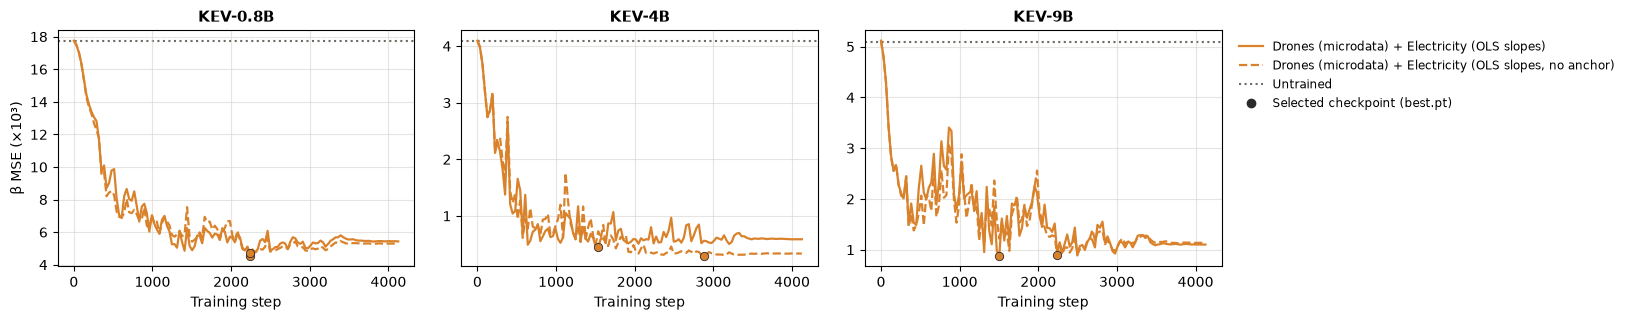

Note. Population β MSE ×10³ on Flights † over training, evaluated every 32 steps; lower is better. Solid lines: KL anchor (α = 0.005); dashed lines: no anchor (α = 0). Dots mark each run's selected checkpoint (best.pt); the dotted line is the untrained model. † Flights (Goldfarb et al., 2026) is the validation set: it selects each run's checkpoint (best.pt) and is the only data set used to judge the anchor. The held-out test sets (Food labels, Grummon et al., 2025; Vaccines, Kreps et al., 2020; Consumer rights, Kantorowicz-Reznichenko et al., 2026; AI & offshoring, Magistro et al., 2025) are left out of this ablation so that they do not inform the method. Missing lines: runs not finished yet.


In [21]:
def plot_anchor_trajectories(anchored_slug: str, no_anchor_slug: str) -> None:
    """Flights † β MSE over training, one panel per model; solid = anchor, dashed = no anchor, dot = best.pt."""
    fig, axes = plt.subplots(1, len(ABLATION_MODELS), figsize=(3.8 * len(ABLATION_MODELS) + 5.0, 3.3), squeeze=False)
    axes = axes[0]
    for ax, model_slug in zip(axes, ABLATION_MODELS):
        base_value = float(regimes_by_model[model_slug].loc[BASE_SLUG, "kriner_mse"]) * MSE_SCALE
        ax.axhline(base_value, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.5, zorder=1)
        for slug, linestyle in ((anchored_slug, "-"), (no_anchor_slug, "--")):
            run_dir = find_run_dir(model_slug, slug)
            if not run_is_finished(run_dir):
                continue
            result = load_paper_run(run_dir)
            series = result.val_history_df["kriner2026/beta_mse"].dropna() * MSE_SCALE
            ax.plot(series.index, series.values, color=STORY_COLORS[slug], linestyle=linestyle, linewidth=1.6, zorder=2)
            best_step = int(result.best["step"])
            best_metrics, _ = result.best_validation["kriner2026"]
            ax.scatter([best_step], [float(best_metrics["beta_mse"]) * MSE_SCALE], s=36, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.6, zorder=3)
        ax.grid(color=NEUTRALS["grid"], alpha=0.6)
        ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
        ax.set_xlabel("Training step")
    axes[0].set_ylabel("β MSE (×10³)")

    legend_handles = [
        plt.Line2D([], [], color=STORY_COLORS[anchored_slug], linestyle="-", linewidth=1.6, label=STORY_LABELS[anchored_slug]),
        plt.Line2D([], [], color=STORY_COLORS[no_anchor_slug], linestyle="--", linewidth=1.6, label=STORY_LABELS[no_anchor_slug]),
        plt.Line2D([], [], color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.5, label=STORY_LABELS[BASE_SLUG]),
        plt.Line2D([], [], color=NEUTRALS["text"], marker="o", linestyle="", markersize=6, label="Selected checkpoint (best.pt)"),
    ]
    axes[-1].legend(handles=legend_handles, fontsize=8.5, loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
    fig.tight_layout()
    plt.show()


TRAJECTORY_NOTE = (
    "Population β MSE ×10³ on Flights † over training, evaluated every 32 steps; lower is better. "
    "Solid lines: KL anchor (α = 0.005); dashed lines: no anchor (α = 0). Dots mark each run's selected checkpoint (best.pt); the dotted line is the untrained model. "
    f"{ABLATION_ROLES_NOTE} Missing lines: runs not finished yet."
)

print_caption("Figure 6", "Flights † Over Training: Electricity (OLS Slopes) With and Without the KL Anchor")
plot_anchor_trajectories("row2_wu_table_anchored", "row2_ablation_wu_table_no_kl")
print_note(TRAJECTORY_NOTE)

print_caption("Figure 7", "Flights † Over Training: Drones (Microdata) + Electricity (OLS Slopes) With and Without the KL Anchor")
plot_anchor_trajectories("row4_hybrid_berke_ce_wu_table_anchored", "row4_hybrid_berke_ce_wu_table_no_kl")
print_note(TRAJECTORY_NOTE)

In [22]:
SWEEP_SPECS = (
    ("a", "kev-0.8b", (LOCAL_PAPER_RUNS_ROOT / "kl_anchor_800m", PAPER_RUNS_ROOT / "kl_anchor_800m")),
    ("b", "kev-9b", (PAPER_RUNS_ROOT / "kl_anchor_9b",)),
)
SWEEP_DRIFT_WINDOW = 20


def format_mse_value(value: float) -> str:
    if np.isnan(value):
        return "NaN"
    return f"{value * MSE_SCALE:.2f}"


def collect_alpha_sweep(sweep_roots: tuple[Path, ...]) -> tuple[pd.DataFrame, list[str], set[float]]:
    """One row per α (plus untrained): KL drift from p₀ near best.pt, and Flights † β MSE at best.pt."""
    run_dirs = []
    for root in sweep_roots:
        for run_dir in sorted(root.iterdir()):
            if (run_dir / "run.json").exists():
                run_dirs.append(run_dir)
    if len(run_dirs) == 0:
        raise FileNotFoundError(f"No α-sweep runs in {sweep_roots}")

    keyed = []
    for run_dir in run_dirs:
        info = run_store.read_run_json(run_dir)
        keyed.append((float(info["identity"]["config"]["kl_anchor_alpha"]), float(info["identity"]["config"]["lr"]), info["status"], run_dir))
    keyed.sort()
    alphas = [alpha for alpha, _, _, _ in keyed]
    if len(set(alphas)) != len(alphas):
        raise ValueError(f"Duplicate α in {sweep_roots}: {alphas}")

    step0 = extract_step0_from_run_dir(keyed[0][3], ("kriner2026",))
    rows = [{
        "α": "Untrained",
        "KL drift from p₀": "0.00",
        "Flights †": format_mse_value(float(step0["metrics"]["kriner2026/beta_mse"])),
    }]
    status_notes = []
    learning_rates = set()
    for alpha, lr, status, run_dir in keyed:
        result = load_paper_run(run_dir)
        if status != run_store.STATUS_FINISHED:
            rows.append({"α": f"{alpha:g}", "KL drift from p₀": "NaN", "Flights †": "NaN"})
            status_notes.append(f"α = {alpha:g} was {status} at step {len(result.step_df)} and is not reported (NaN).")
            continue
        learning_rates.add(lr)
        best_step = int(result.best["step"])
        drift = result.step_df.loc[result.step_df.index <= best_step, "kl_anchor_loss"].dropna().tail(SWEEP_DRIFT_WINDOW)
        kriner_metrics, _ = result.best_validation["kriner2026"]
        rows.append({
            "α": f"{alpha:g}",
            "KL drift from p₀": f"{float(drift.mean()):.2f}",
            "Flights †": format_mse_value(float(kriner_metrics["beta_mse"])),
        })
    return pd.DataFrame(rows).set_index("α"), status_notes, learning_rates


for letter, model_slug, sweep_roots in SWEEP_SPECS:
    sweep_df, status_notes, learning_rates = collect_alpha_sweep(sweep_roots)
    lr_text = ", ".join(f"{lr:g}" for lr in sorted(learning_rates))
    print_caption(f"Table 5{letter}", f"KL Anchor Weight Sweep on Electricity (OLS Slopes): {MODEL_DISPLAY[model_slug]}")
    display(sweep_df)
    print_note(
        f"Each row is one Electricity (OLS slopes) run with KL anchor weight α (α = 0: no anchor). "
        f"KL drift from p₀ = mean KL(p₀‖p_θ) on Electricity (Wu, 2025) tasks over the {SWEEP_DRIFT_WINDOW} logged steps up to best.pt (logged even when α = 0). "
        f"Flights † = population β MSE ×10³ at best.pt; lower is better. Learning rate: {lr_text}. "
        + "".join(f"{status_note} " for status_note in status_notes) + ABLATION_ROLES_NOTE
    )

Table 5a
KL Anchor Weight Sweep on Electricity (OLS Slopes): KEV-0.8B


,KL drift from p₀,Flights †
α,,
Untrained,0.00,17.75
0,4.65,4.10
0.002,1.53,4.20
0.005,1.02,3.52
0.02,0.43,5.85
0.1,0.19,6.29
0.5,NaN,NaN


Note. Each row is one Electricity (OLS slopes) run with KL anchor weight α (α = 0: no anchor). KL drift from p₀ = mean KL(p₀‖p_θ) on Electricity (Wu, 2025) tasks over the 20 logged steps up to best.pt (logged even when α = 0). Flights † = population β MSE ×10³ at best.pt; lower is better. Learning rate: 1e-05. α = 0.5 was interrupted at step 1350 and is not reported (NaN). † Flights (Goldfarb et al., 2026) is the validation set: it selects each run's checkpoint (best.pt) and is the only data set used to judge the anchor. The held-out test sets (Food labels, Grummon et al., 2025; Vaccines, Kreps et al., 2020; Consumer rights, Kantorowicz-Reznichenko et al., 2026; AI & offshoring, Magistro et al., 2025) are left out of this ablation so that they do not inform the method.
Table 5b
KL Anchor Weight Sweep on Electricity (OLS Slopes): KEV-9B


,KL drift from p₀,Flights †
α,,
Untrained,0.00,5.09
0,1.65,0.99
0.002,0.92,1.49
0.005,0.66,1.58
0.01,0.60,1.99
0.05,0.23,2.21


Note. Each row is one Electricity (OLS slopes) run with KL anchor weight α (α = 0: no anchor). KL drift from p₀ = mean KL(p₀‖p_θ) on Electricity (Wu, 2025) tasks over the 20 logged steps up to best.pt (logged even when α = 0). Flights † = population β MSE ×10³ at best.pt; lower is better. Learning rate: 5e-06. † Flights (Goldfarb et al., 2026) is the validation set: it selects each run's checkpoint (best.pt) and is the only data set used to judge the anchor. The held-out test sets (Food labels, Grummon et al., 2025; Vaccines, Kreps et al., 2020; Consumer rights, Kantorowicz-Reznichenko et al., 2026; AI & offshoring, Magistro et al., 2025) are left out of this ablation so that they do not inform the method.


---
## Appendix — Choice KL for Tables 1–3 (Tables A2–A4)

In [19]:
table_a2_df = relabel_rows(build_metric_table(STEP1_MODELS, STEP1_SLUGS, "kl", STORY_COLUMNS).round(3))
print_caption("Table A2", "Choice KL for Table 1")
display(table_a2_df)
print_note(f"Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. {ROLES_NOTE} NaN = run or held-out test evaluation not finished yet.")

table_a3_df = relabel_rows(build_metric_table(STEP2_MODELS, STEP2_SLUGS, "kl", STORY_COLUMNS).round(3))
print_caption("Table A3", "Choice KL for Table 2")
display(table_a3_df)
print_note(f"Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. {ROLES_NOTE} NaN = run or held-out test evaluation not finished yet.")

table_a4_df = relabel_rows(build_metric_table(STEP3_MODELS, STEP3_SLUGS, "kl", STORY_COLUMNS).round(3))
print_caption("Table A4", "Choice KL for Table 3")
display(table_a4_df)
print_note(f"Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. {ROLES_NOTE} NaN = run or held-out test evaluation not finished yet.")

Table A2
Choice KL for Table 1


Food labels  Vaccines  Consumer rights  AI & offshoring  Flights †
Model    Trained on                                                                                          
KEV-0.8B Untrained                               1.059     1.185            1.418            2.283      1.086
         Electricity (microdata)                 0.915     1.082            0.821            1.689      0.693
         Drones (microdata)                      0.953     1.105            0.806            1.630      0.709
         Drones + Electricity (microdata)        0.879     1.067            0.695            1.558      0.647
KEV-4B   Untrained                               1.100     1.525            0.779              NaN      0.811
         Electricity (microdata)                 0.887     1.120              NaN              NaN      0.625
         Drones (microdata)                      0.959     1.195              NaN              NaN      0.623
         Drones + Electricity (microdata)        0.854     1.046              NaN              NaN      0.588
KEV-9B   Untrained                               1.238     1.422              NaN              NaN      0.832
         Electricity (microdata)                 0.972     1.203              NaN              NaN      0.647
         Drones (microdata)                      0.963     1.165              NaN              NaN      0.646
         Drones + Electricity (microdata)        0.808     1.100              NaN              NaN      0.604

Note. Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run or held-out test evaluation not finished yet.
Table A3
Choice KL for Table 2


Food labels  Vaccines  Consumer rights  AI & offshoring  Flights †
Model    Trained on                                                                                  
KEV-0.8B Untrained                       1.059     1.185            1.418            2.283      1.086
         Electricity (OLS slopes)        0.965     1.141            0.905            1.759      0.791
         Electricity (microdata)         0.915     1.082            0.821            1.689      0.693
KEV-4B   Untrained                       1.100     1.525            0.779              NaN      0.811
         Electricity (OLS slopes)        0.871     1.202              NaN              NaN      0.612
         Electricity (microdata)         0.887     1.120              NaN              NaN      0.625
KEV-9B   Untrained                       1.238     1.422              NaN              NaN      0.832
         Electricity (OLS slopes)        0.911     1.233              NaN              NaN      0.669
         Electricity (microdata)         0.972     1.203              NaN              NaN      0.647

Note. Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run or held-out test evaluation not finished yet.
Table A4
Choice KL for Table 3


Food labels  Vaccines  Consumer rights  AI & offshoring  Flights †
Model    Trained on                                                                                                       
KEV-0.8B Untrained                                            1.059     1.185            1.418            2.283      1.086
         Drones (microdata)                                   0.953     1.105            0.806            1.630      0.709
         Drones (microdata) + Electricity (OLS slopes)        0.911     1.092            0.753            1.571      0.675
         Drones + Electricity (microdata)                     0.879     1.067            0.695            1.558      0.647
KEV-4B   Untrained                                            1.100     1.525            0.779              NaN      0.811
         Drones (microdata)                                   0.959     1.195              NaN              NaN      0.623
         Drones (microdata) + Electricity (OLS slopes)        0.849     1.122              NaN              NaN      0.614
         Drones + Electricity (microdata)                     0.854     1.046              NaN              NaN      0.588
KEV-9B   Untrained                                            1.238     1.422              NaN              NaN      0.832
         Drones (microdata)                                   0.963     1.165              NaN              NaN      0.646
         Drones (microdata) + Electricity (OLS slopes)        0.839     1.045              NaN              NaN      0.595
         Drones + Electricity (microdata)                     0.808     1.100              NaN              NaN      0.604

Note. Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run or held-out test evaluation not finished yet.


---
## Appendix — `Vaccines` Slopes by Attribute (Table A5)

In [20]:
KREPS_APPENDIX_SLUGS = (
    "row1_base_untrained",
    "row2_wu_table_anchored",
    "row2_ablation_wu_table_no_kl",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row4_hybrid_berke_ce_wu_table_no_kl",
    "row5_full_berke_wu_ce_oracle",
)

for model_index, model_slug in enumerate(STEP4_MODELS):
    betas_by_slug = covid_betas_by_model[model_slug]
    columns = {"Human (OLS)": betas_by_slug[BASE_SLUG]["human_pop_beta"]}
    for slug in KREPS_APPENDIX_SLUGS:
        if slug in betas_by_slug:
            columns[STORY_LABELS[slug]] = betas_by_slug[slug]["model_pop_beta"]
        else:
            columns[STORY_LABELS[slug]] = pd.Series(np.nan, index=columns["Human (OLS)"].index)
    kreps_term_df = pd.DataFrame(columns)
    kreps_term_df.index.name = "Vaccine attribute level"
    squared_error = kreps_term_df.sub(kreps_term_df["Human (OLS)"], axis=0).pow(2)
    kreps_term_df.loc["β MSE vs. human"] = squared_error.mean()
    print_caption(f"Table A5{TABLE_LETTERS[model_index]}", f"Vaccines Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(kreps_term_df.round(4))
    print_note("Vaccines (Kreps et al., 2020) is a held-out test set. Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human. Includes runs without the KL anchor. NaN = run not finished yet.")

Table A5a
Vaccines Population β by Attribute: KEV-0.8B


,Human (OLS),Untrained,Electricity (OLS slopes),"Electricity (OLS slopes, no anchor)",Electricity (microdata),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),"Drones (microdata) + Electricity (OLS slopes, no anchor)",Drones + Electricity (microdata)
Vaccine attribute level,,,,,,,,,
Efficacy: 70% vs 50%,0.0744,0.0420,0.0377,0.0676,0.0539,0.0363,0.0498,0.0501,0.0556
Efficacy: 90% vs 50%,0.1641,0.0650,0.0740,0.1174,0.0957,0.0619,0.0928,0.0867,0.1035
Duration: 5y vs 1y,0.0541,0.0169,0.0312,0.0505,0.0278,0.0093,0.0235,0.0216,0.0230
Severe side effects: 1/1M vs 1/10k,0.0653,0.0094,0.0179,0.0254,0.0195,0.0133,0.0219,0.0171,0.0240
Mild side effects: 1/30 vs 1/10,0.0125,-0.0005,-0.0052,-0.0075,-0.0043,-0.0065,-0.0092,-0.0094,-0.0090
FDA: EUA vs Full approval,-0.0287,0.0340,0.0251,0.0303,0.0193,0.0243,0.0256,0.0307,0.0174
Origin: UK vs US,-0.0380,-0.0253,-0.0322,-0.0395,-0.0255,-0.0292,-0.0346,-0.0366,-0.0297
Origin: China vs US,-0.1308,0.0279,0.0002,0.0163,0.0068,0.0068,0.0048,-0.0055,-0.0037
Endorsed: Biden vs Trump,0.0181,0.1092,0.1713,0.2324,0.0910,0.0592,0.0937,0.1060,0.0628


Note. Vaccines (Kreps et al., 2020) is a held-out test set. Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human. Includes runs without the KL anchor. NaN = run not finished yet.
Table A5b
Vaccines Population β by Attribute: KEV-4B


,Human (OLS),Untrained,Electricity (OLS slopes),"Electricity (OLS slopes, no anchor)",Electricity (microdata),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),"Drones (microdata) + Electricity (OLS slopes, no anchor)",Drones + Electricity (microdata)
Vaccine attribute level,,,,,,,,,
Efficacy: 70% vs 50%,0.0744,0.1253,0.1181,0.1243,0.1130,0.1267,0.0930,0.1055,0.1086
Efficacy: 90% vs 50%,0.1641,0.2377,0.2221,0.2376,0.2148,0.2446,0.1760,0.2024,0.2113
Duration: 5y vs 1y,0.0541,0.0046,0.0246,0.0114,0.0325,0.0183,0.0301,0.0356,0.0383
Severe side effects: 1/1M vs 1/10k,0.0653,0.0235,0.0294,0.0274,0.0324,0.0376,0.0335,0.0355,0.0450
Mild side effects: 1/30 vs 1/10,0.0125,0.0080,0.0136,0.0087,0.0177,0.0094,0.0123,0.0080,0.0181
FDA: EUA vs Full approval,-0.0287,-0.0678,-0.0549,-0.0705,-0.0477,-0.0621,-0.0521,-0.0502,-0.0385
Origin: UK vs US,-0.0380,-0.0812,-0.0686,-0.0765,-0.0553,-0.0891,-0.0628,-0.0604,-0.0529
Origin: China vs US,-0.1308,-0.1969,-0.1633,-0.1796,-0.1214,-0.1910,-0.1622,-0.1569,-0.1143
Endorsed: Biden vs Trump,0.0181,0.0503,0.0674,0.0512,-0.0007,0.0569,0.0833,0.0813,0.0463


Note. Vaccines (Kreps et al., 2020) is a held-out test set. Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human. Includes runs without the KL anchor. NaN = run not finished yet.
Table A5c
Vaccines Population β by Attribute: KEV-9B


,Human (OLS),Untrained,Electricity (OLS slopes),"Electricity (OLS slopes, no anchor)",Electricity (microdata),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),"Drones (microdata) + Electricity (OLS slopes, no anchor)",Drones + Electricity (microdata)
Vaccine attribute level,,,,,,,,,
Efficacy: 70% vs 50%,0.0744,0.2110,0.2177,0.2709,0.1715,0.1865,0.1570,0.1785,0.1541
Efficacy: 90% vs 50%,0.1641,0.3693,0.4066,0.4918,0.3165,0.3322,0.2861,0.3211,0.2895
Duration: 5y vs 1y,0.0541,0.0253,0.0432,0.0528,0.0335,0.0372,0.0403,0.0442,0.0459
Severe side effects: 1/1M vs 1/10k,0.0653,0.0502,0.0790,0.1102,0.0522,0.0549,0.0612,0.0749,0.0542
Mild side effects: 1/30 vs 1/10,0.0125,0.0156,0.0206,0.0259,0.0190,0.0148,0.0152,0.0161,0.0201
FDA: EUA vs Full approval,-0.0287,-0.0077,-0.0165,-0.0232,-0.0144,-0.0079,-0.0157,-0.0150,-0.0128
Origin: UK vs US,-0.0380,-0.0717,-0.0448,-0.0531,-0.0589,-0.0563,-0.0503,-0.0477,-0.0506
Origin: China vs US,-0.1308,-0.2047,-0.1582,-0.1676,-0.1656,-0.1598,-0.1418,-0.1521,-0.1432
Endorsed: Biden vs Trump,0.0181,0.1179,0.1285,0.1516,0.0524,0.1089,0.1166,0.1287,0.0396


Note. Vaccines (Kreps et al., 2020) is a held-out test set. Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human. Includes runs without the KL anchor. NaN = run not finished yet.


---
## Appendix — `Flights †` Slopes by Attribute (Table A6)

In [21]:
for model_index, model_slug in enumerate(STEP4_MODELS):
    betas_by_slug = kriner_betas_by_model[model_slug]
    columns = {"Human (OLS)": betas_by_slug[STEP4_SLUGS[0]].loc[kriner_terms, "human_pop_beta"]}
    for slug in STEP4_SLUGS:
        columns[STORY_LABELS[slug]] = betas_by_slug[slug].loc[kriner_terms, "model_pop_beta"]
    kriner_term_df = pd.DataFrame(columns)
    kriner_term_df.index.name = "Flight attribute level"
    squared_error = kriner_term_df.sub(kriner_term_df["Human (OLS)"], axis=0).pow(2)
    kriner_term_df.loc["β MSE vs. human"] = squared_error.mean()
    print_caption(f"Table A6{TABLE_LETTERS[model_index]}", f"Flights † Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(kriner_term_df.round(4))
    print_note("Values behind Figures 4 and 5 (Price and sustainable aviation fuel listed first). Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human. † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.")

Table A6a
Flights † Population β by Attribute: KEV-0.8B


,Human (OLS),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),Drones + Electricity (microdata)
Flight attribute level,,,,
Price: $275,-0.0853,-0.0327,-0.0688,-0.0701
Price: $300,-0.1953,-0.0816,-0.1639,-0.1519
Price: $325,-0.3040,-0.1210,-0.2431,-0.2335
Fuel: Sustainable aviation fuel,0.0691,-0.0258,-0.0062,0.0096
Airline: Frontier,-0.0854,0.0175,0.0049,0.0055
Airline: Southwest,-0.0238,0.0103,0.0039,0.0026
Airline: United,-0.0220,0.0029,0.0012,0.0021
Baggage: Checked bag+carry-on,0.0561,-0.0408,-0.0324,-0.0257
Baggage: Personal item only,-0.1393,-0.0084,-0.0206,-0.0145


Note. Values behind Figures 4 and 5 (Price and sustainable aviation fuel listed first). Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human. † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.
Table A6b
Flights † Population β by Attribute: KEV-4B


,Human (OLS),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),Drones + Electricity (microdata)
Flight attribute level,,,,
Price: $275,-0.0853,-0.0821,-0.0929,-0.0884
Price: $300,-0.1953,-0.1552,-0.1887,-0.1864
Price: $325,-0.3040,-0.2441,-0.2935,-0.2802
Fuel: Sustainable aviation fuel,0.0691,0.0873,0.0798,0.0788
Airline: Frontier,-0.0854,-0.1218,-0.0928,-0.0886
Airline: Southwest,-0.0238,0.0153,0.0083,0.0116
Airline: United,-0.0220,-0.0121,-0.0087,-0.0100
Baggage: Checked bag+carry-on,0.0561,0.0658,0.0614,0.0687
Baggage: Personal item only,-0.1393,-0.1259,-0.0952,-0.0919


Note. Values behind Figures 4 and 5 (Price and sustainable aviation fuel listed first). Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human. † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.
Table A6c
Flights † Population β by Attribute: KEV-9B


,Human (OLS),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),Drones + Electricity (microdata)
Flight attribute level,,,,
Price: $275,-0.0853,-0.0453,-0.0668,-0.0685
Price: $300,-0.1953,-0.1108,-0.1651,-0.1716
Price: $325,-0.3040,-0.1847,-0.2547,-0.2645
Fuel: Sustainable aviation fuel,0.0691,0.0239,0.0415,0.0486
Airline: Frontier,-0.0854,-0.1044,-0.0856,-0.0918
Airline: Southwest,-0.0238,0.0152,0.0135,0.0360
Airline: United,-0.0220,-0.0132,-0.0105,-0.0118
Baggage: Checked bag+carry-on,0.0561,0.0986,0.0842,0.0885
Baggage: Personal item only,-0.1393,-0.1167,-0.0980,-0.1031


Note. Values behind Figures 4 and 5 (Price and sustainable aviation fuel listed first). Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human. † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.


---
## Appendix — Choice KL for Table 4 (Table A7)

In [22]:
for letter, title, anchored_slug, no_anchor_slug in ABLATION_PAIRS:
    table_a7_df = relabel_rows(build_metric_table(ABLATION_MODELS, (BASE_SLUG, anchored_slug, no_anchor_slug), "kl", ABLATION_COLUMNS).round(3))
    print_caption(f"Table A7{letter}", f"Choice KL for Table 4{letter}")
    display(table_a7_df)
    print_note(f"Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. {ABLATION_ROLES_NOTE} NaN = run not finished yet.")

Table A7a
Choice KL for Table 4a


Flights †
Model    Trained on                                    
KEV-0.8B Untrained                                1.086
         Electricity (OLS slopes)                 0.791
         Electricity (OLS slopes, no anchor)      0.815
KEV-4B   Untrained                                0.811
         Electricity (OLS slopes)                 0.612
         Electricity (OLS slopes, no anchor)      0.673
KEV-9B   Untrained                                0.832
         Electricity (OLS slopes)                 0.669
         Electricity (OLS slopes, no anchor)      0.782

Note. Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. † Flights (Goldfarb et al., 2026) is the validation set: it selects each run's checkpoint (best.pt) and is the only data set used to judge the anchor. The held-out test sets (Food labels, Grummon et al., 2025; Vaccines, Kreps et al., 2020; Consumer rights, Kantorowicz-Reznichenko et al., 2026; AI & offshoring, Magistro et al., 2025) are left out of this ablation so that they do not inform the method. NaN = run not finished yet.
Table A7b
Choice KL for Table 4b


Flights †
Model    Trained on                                                         
KEV-0.8B Untrained                                                     1.086
         Drones (microdata) + Electricity (OLS slopes)                 0.675
         Drones (microdata) + Electricity (OLS slopes, no anchor)      0.668
KEV-4B   Untrained                                                     0.811
         Drones (microdata) + Electricity (OLS slopes)                 0.614
         Drones (microdata) + Electricity (OLS slopes, no anchor)      0.620
KEV-9B   Untrained                                                     0.832
         Drones (microdata) + Electricity (OLS slopes)                 0.595
         Drones (microdata) + Electricity (OLS slopes, no anchor)      0.646

Note. Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. † Flights (Goldfarb et al., 2026) is the validation set: it selects each run's checkpoint (best.pt) and is the only data set used to judge the anchor. The held-out test sets (Food labels, Grummon et al., 2025; Vaccines, Kreps et al., 2020; Consumer rights, Kantorowicz-Reznichenko et al., 2026; AI & offshoring, Magistro et al., 2025) are left out of this ablation so that they do not inform the method. NaN = run not finished yet.


---
## Appendix — `Consumer rights` Slopes by Attribute (Table A8)

In [23]:
# Canonical Human (OLS) slopes for Consumer rights from the first evaluated model (cross-checked across all evaluated models)
k26_human_reference = None
for model_slug in STEP4_MODELS:
    if BASE_SLUG in kantorowicz_betas_by_model[model_slug]:
        ref_df = kantorowicz_betas_by_model[model_slug][BASE_SLUG][["model", "human_pop_beta"]]
        if k26_human_reference is None:
            k26_human_reference = ref_df
        else:
            if list(ref_df.index) != list(k26_human_reference.index):
                raise ValueError(f"{model_slug}: Consumer rights term index mismatch")
            max_diff = float((ref_df["human_pop_beta"] - k26_human_reference["human_pop_beta"]).abs().max())
            if max_diff > 1e-12:
                raise ValueError(f"{model_slug}: Consumer rights human_pop_beta mismatch (max_diff={max_diff})")
if k26_human_reference is None:
    raise FileNotFoundError("No model has kantorowicz2026 in test_best/ yet")

k26_price_mask = pd.Series(
    [kantorowicz_attr_group(t) == "price" for t in k26_human_reference.index],
    index=k26_human_reference.index,
)

for model_index, model_slug in enumerate(STEP4_MODELS):
    betas_by_slug = kantorowicz_betas_by_model[model_slug]
    columns = {"Human (OLS)": k26_human_reference["human_pop_beta"]}
    for slug in KREPS_APPENDIX_SLUGS:
        if slug in betas_by_slug:
            columns[STORY_LABELS[slug]] = betas_by_slug[slug].loc[k26_human_reference.index, "model_pop_beta"]
        else:
            columns[STORY_LABELS[slug]] = pd.Series(np.nan, index=k26_human_reference.index)
    k26_term_df = pd.DataFrame(columns)
    k26_term_df.index.name = "Consumer rights attribute level"
    squared_error = k26_term_df.sub(k26_term_df["Human (OLS)"], axis=0).pow(2)
    k26_term_df.loc["Price β MSE vs. human (4)"] = squared_error.loc[k26_price_mask].mean()
    k26_term_df.loc["Non-price β MSE vs. human (34)"] = squared_error.loc[~k26_price_mask].mean()
    k26_term_df.loc["Overall β MSE vs. human (38)"] = squared_error.mean()
    print_caption(f"Table A8{TABLE_LETTERS[model_index]}", f"Consumer Rights Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(k26_term_df.round(4))
    print_note(
        "Consumer rights (Kantorowicz-Reznichenko et al., 2026) is a held-out test set spanning 19 laptop and 19 laundry-machine AMCEs (38 total). "
        "Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (4), Non-price (34), and Overall (38) β MSE versus human. "
        "Includes runs without the KL anchor. NaN = held-out Consumer rights evaluation not finished yet."
    )

Table A8a
Consumer Rights Population β by Attribute: KEV-0.8B


,Human (OLS),Untrained,Electricity (OLS slopes),"Electricity (OLS slopes, no anchor)",Electricity (microdata),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),"Drones (microdata) + Electricity (OLS slopes, no anchor)",Drones + Electricity (microdata)
Consumer rights attribute level,,,,,,,,,
Computers | Price: $1250 vs $2000,0.0970,0.0032,0.0101,0.0093,-0.0060,0.0068,0.0026,0.0112,0.0005
Computers | Price: $500 vs $2000,0.2200,0.0113,0.0300,0.0247,-0.0002,0.0399,0.0268,0.0470,0.0258
Computers | Brand: Apple MacBook vs Medion,0.0315,-0.0116,-0.0259,-0.0372,-0.0024,0.0009,0.0003,0.0006,0.0138
Computers | Brand: Lenovo vs Medion,0.0462,-0.0063,-0.0091,-0.0131,-0.0014,-0.0027,-0.0027,-0.0027,0.0016
Computers | Brand: HP vs Medion,0.0799,-0.0009,-0.0028,-0.0044,0.0025,0.0008,-0.0003,-0.0001,0.0014
Computers | RAM: 10 GB vs 4 GB,0.0922,-0.0005,-0.0024,-0.0010,0.0152,0.0026,0.0126,0.0150,0.0176
Computers | RAM: 16 GB vs 4 GB,0.1472,0.0081,0.0042,0.0088,0.0356,0.0110,0.0269,0.0316,0.0364
Computers | Storage: 256 GB vs 128 GB,0.0631,0.0004,-0.0013,-0.0008,0.0025,-0.0004,0.0024,0.0018,0.0023
Computers | Storage: 512 GB vs 128 GB,0.1186,-0.0088,-0.0067,-0.0051,0.0054,-0.0043,0.0044,0.0051,0.0070


Note. Consumer rights (Kantorowicz-Reznichenko et al., 2026) is a held-out test set spanning 19 laptop and 19 laundry-machine AMCEs (38 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (4), Non-price (34), and Overall (38) β MSE versus human. Includes runs without the KL anchor. NaN = held-out Consumer rights evaluation not finished yet.
Table A8b
Consumer Rights Population β by Attribute: KEV-4B


,Human (OLS),Untrained,Electricity (OLS slopes),"Electricity (OLS slopes, no anchor)",Electricity (microdata),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),"Drones (microdata) + Electricity (OLS slopes, no anchor)",Drones + Electricity (microdata)
Consumer rights attribute level,,,,,,,,,
Computers | Price: $1250 vs $2000,0.0970,0.0367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Price: $500 vs $2000,0.2200,0.0265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Brand: Apple MacBook vs Medion,0.0315,-0.0226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Brand: Lenovo vs Medion,0.0462,0.0128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Brand: HP vs Medion,0.0799,0.0118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | RAM: 10 GB vs 4 GB,0.0922,0.0121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | RAM: 16 GB vs 4 GB,0.1472,0.0454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Storage: 256 GB vs 128 GB,0.0631,0.0310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Storage: 512 GB vs 128 GB,0.1186,0.0458,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Note. Consumer rights (Kantorowicz-Reznichenko et al., 2026) is a held-out test set spanning 19 laptop and 19 laundry-machine AMCEs (38 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (4), Non-price (34), and Overall (38) β MSE versus human. Includes runs without the KL anchor. NaN = held-out Consumer rights evaluation not finished yet.
Table A8c
Consumer Rights Population β by Attribute: KEV-9B


,Human (OLS),Untrained,Electricity (OLS slopes),"Electricity (OLS slopes, no anchor)",Electricity (microdata),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),"Drones (microdata) + Electricity (OLS slopes, no anchor)",Drones + Electricity (microdata)
Consumer rights attribute level,,,,,,,,,
Computers | Price: $1250 vs $2000,0.0970,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Price: $500 vs $2000,0.2200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Brand: Apple MacBook vs Medion,0.0315,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Brand: Lenovo vs Medion,0.0462,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Brand: HP vs Medion,0.0799,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | RAM: 10 GB vs 4 GB,0.0922,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | RAM: 16 GB vs 4 GB,0.1472,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Storage: 256 GB vs 128 GB,0.0631,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Computers | Storage: 512 GB vs 128 GB,0.1186,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Note. Consumer rights (Kantorowicz-Reznichenko et al., 2026) is a held-out test set spanning 19 laptop and 19 laundry-machine AMCEs (38 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (4), Non-price (34), and Overall (38) β MSE versus human. Includes runs without the KL anchor. NaN = held-out Consumer rights evaluation not finished yet.


---
## Appendix — `AI & offshoring` Slopes by Attribute (Table A9)

In [24]:
from beta_ols.core import fit_human_ols

# Canonical Human (OLS) slopes for AI & offshoring, cross-checked against any evaluated model's test_best/
m25_choice_df = ds_magistro.load_choice_df()
m25_rows = ds_magistro.regression_rows(m25_choice_df)
m25_ols = fit_human_ols(m25_rows, ds_magistro.regression_specs(m25_rows))
m25_human_reference = m25_ols.set_index("term")[["model", "human_beta"]].rename(
    columns={"human_beta": "human_pop_beta"}
)

for model_slug in STEP4_MODELS:
    if BASE_SLUG in magistro_betas_by_model[model_slug]:
        ref_df = magistro_betas_by_model[model_slug][BASE_SLUG][["model", "human_pop_beta"]]
        if list(ref_df.index) != list(m25_human_reference.index):
            raise ValueError(f"{model_slug}: AI & offshoring term index mismatch")
        max_diff = float((ref_df["human_pop_beta"] - m25_human_reference["human_pop_beta"]).abs().max())
        if max_diff > 1e-12:
            raise ValueError(f"{model_slug}: AI & offshoring human_pop_beta mismatch (max_diff={max_diff})")

m25_price_mask = pd.Series(
    [magistro_attr_group(t) == "price" for t in m25_human_reference.index],
    index=m25_human_reference.index,
)

for model_index, model_slug in enumerate(STEP4_MODELS):
    betas_by_slug = magistro_betas_by_model[model_slug]
    columns = {"Human (OLS)": m25_human_reference["human_pop_beta"]}
    for slug in KREPS_APPENDIX_SLUGS:
        if slug in betas_by_slug:
            columns[STORY_LABELS[slug]] = betas_by_slug[slug].loc[m25_human_reference.index, "model_pop_beta"]
        else:
            columns[STORY_LABELS[slug]] = pd.Series(np.nan, index=m25_human_reference.index)
    m25_term_df = pd.DataFrame(columns)
    m25_term_df.index.name = "AI & offshoring attribute level"
    squared_error = m25_term_df.sub(m25_term_df["Human (OLS)"], axis=0).pow(2)
    m25_term_df.loc["Price β MSE vs. human (8)"] = squared_error.loc[m25_price_mask].mean()
    m25_term_df.loc["Non-price β MSE vs. human (24)"] = squared_error.loc[~m25_price_mask].mean()
    m25_term_df.loc["Overall β MSE vs. human (32)"] = squared_error.mean()
    print_caption(f"Table A9{TABLE_LETTERS[model_index]}", f"AI & Offshoring Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(m25_term_df.round(4))
    print_note(
        "AI & offshoring (Magistro et al., 2025) is a held-out test set spanning 4 country × arm regressions of 8 AMCEs each (32 total). "
        "Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (8), Non-price (24), and Overall (32) β MSE versus human. "
        "Includes runs without the KL anchor. NaN = held-out AI & offshoring evaluation not finished yet."
    )

Table A9a
AI & Offshoring Population β by Attribute: KEV-0.8B


,Human (OLS),Untrained,Electricity (OLS slopes),"Electricity (OLS slopes, no anchor)",Electricity (microdata),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),"Drones (microdata) + Electricity (OLS slopes, no anchor)",Drones + Electricity (microdata)
AI & offshoring attribute level,,,,,,,,,
US AI | Price: $450 vs $600,0.3134,-0.0015,0.0352,-0.0092,0.0183,0.0055,0.0013,0.0011,0.0308
US AI | Price: $300 vs $600,0.3513,-0.0133,0.0224,-0.0155,0.0135,-0.0271,-0.0094,-0.0257,0.0220
US AI | Customer service jobs: 75 vs 100,-0.1975,-0.0105,-0.0470,-0.0437,-0.0343,-0.0159,-0.0460,-0.0577,-0.0539
US AI | Customer service jobs: 125 vs 100,0.0725,0.0368,0.0840,0.0797,0.0622,0.0702,0.0643,0.0651,0.0608
US AI | Factory jobs: 300 vs 400,-0.3894,-0.0777,-0.1853,-0.1834,-0.1134,-0.0922,-0.1343,-0.1336,-0.1254
US AI | Factory jobs: 500 vs 400,0.1402,0.0276,0.0711,0.0570,0.0565,0.0542,0.0621,0.0641,0.0718
US AI | Data science jobs: 150 vs 200,-0.2153,-0.0548,-0.1600,-0.1301,-0.0891,-0.0512,-0.0972,-0.0974,-0.0873
US AI | Data science jobs: 250 vs 200,0.0748,0.1093,0.2847,0.2626,0.1788,0.1457,0.2046,0.1946,0.1604
US Offshoring | Price: $450 vs $600,0.2272,0.0050,0.0065,-0.0134,-0.0004,0.0105,-0.0064,-0.0130,0.0160


Note. AI & offshoring (Magistro et al., 2025) is a held-out test set spanning 4 country × arm regressions of 8 AMCEs each (32 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (8), Non-price (24), and Overall (32) β MSE versus human. Includes runs without the KL anchor. NaN = held-out AI & offshoring evaluation not finished yet.
Table A9b
AI & Offshoring Population β by Attribute: KEV-4B


,Human (OLS),Untrained,Electricity (OLS slopes),"Electricity (OLS slopes, no anchor)",Electricity (microdata),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),"Drones (microdata) + Electricity (OLS slopes, no anchor)",Drones + Electricity (microdata)
AI & offshoring attribute level,,,,,,,,,
US AI | Price: $450 vs $600,0.3134,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Price: $300 vs $600,0.3513,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Customer service jobs: 75 vs 100,-0.1975,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Customer service jobs: 125 vs 100,0.0725,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Factory jobs: 300 vs 400,-0.3894,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Factory jobs: 500 vs 400,0.1402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Data science jobs: 150 vs 200,-0.2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Data science jobs: 250 vs 200,0.0748,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US Offshoring | Price: $450 vs $600,0.2272,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Note. AI & offshoring (Magistro et al., 2025) is a held-out test set spanning 4 country × arm regressions of 8 AMCEs each (32 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (8), Non-price (24), and Overall (32) β MSE versus human. Includes runs without the KL anchor. NaN = held-out AI & offshoring evaluation not finished yet.
Table A9c
AI & Offshoring Population β by Attribute: KEV-9B


,Human (OLS),Untrained,Electricity (OLS slopes),"Electricity (OLS slopes, no anchor)",Electricity (microdata),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),"Drones (microdata) + Electricity (OLS slopes, no anchor)",Drones + Electricity (microdata)
AI & offshoring attribute level,,,,,,,,,
US AI | Price: $450 vs $600,0.3134,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Price: $300 vs $600,0.3513,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Customer service jobs: 75 vs 100,-0.1975,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Customer service jobs: 125 vs 100,0.0725,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Factory jobs: 300 vs 400,-0.3894,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Factory jobs: 500 vs 400,0.1402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Data science jobs: 150 vs 200,-0.2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US AI | Data science jobs: 250 vs 200,0.0748,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
US Offshoring | Price: $450 vs $600,0.2272,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Note. AI & offshoring (Magistro et al., 2025) is a held-out test set spanning 4 country × arm regressions of 8 AMCEs each (32 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (8), Non-price (24), and Overall (32) β MSE versus human. Includes runs without the KL anchor. NaN = held-out AI & offshoring evaluation not finished yet.
